# Predicting Diabetes and Prediabetes from Routine Health Survey Answers

**Author:** Henriette Biziyaremye  
**Course:** Machine Learning, Summative Assignment (Model Training and Evaluation)

**GitHub:** _add link_ | **Google Drive (data + saved models):** _add link_ | **Video:** _add link_

---

Diabetes often goes unnoticed for years. The International Diabetes Federation estimates that a large share of adults living with diabetes in Africa have never been diagnosed, and prediabetes, the stage where lifestyle changes can still prevent the disease, is even harder to catch because it rarely causes symptoms. Blood tests are the gold standard, but they cost money and require a clinic visit.

The question I want to answer in this project is simple: **can a person's answers to a short health survey tell us whether they are likely to have diabetes or prediabetes?** If that works reasonably well, it could act as a cheap first screening step that helps decide who should be sent for a proper blood test.

I use the CDC Diabetes Health Indicators dataset, built from the 2015 Behavioral Risk Factor Surveillance System (BRFSS). It has 253,680 survey responses and a three-class target: no diabetes, prediabetes, and diabetes.

**How this notebook is organised**

1. Data loading, exploration and preprocessing (this part)
2. Traditional machine learning with scikit-learn
3. Deep learning with TensorFlow/Keras and `tf.data`
4. Comparison, error analysis and conclusions

## 1. Setup

Everything that involves randomness (the data split, model initialisation, sampling) uses the same seed so the results in my report can be reproduced exactly. The reusable preprocessing code lives in `src/preprocessing.py`, which keeps this notebook readable and lets me save and reload the fitted pipeline later.

If you are running this on Colab, clone the repository first and run the notebook from the repository root so `src/` can be imported.

In [3]:
import os, sys, glob, importlib
os.chdir("/content")

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

matches = glob.glob("/content/drive/MyDrive/**/src/experiments.py", recursive=True)
print("Found:", matches)

project_dir = os.path.dirname(os.path.dirname(matches[0]))
os.chdir(project_dir)
sys.path.insert(0, project_dir)
importlib.invalidate_caches()

print("Working in:", os.getcwd())
print(os.listdir("src"))
import src.experiments, src.deep_learning
print("OK")

Mounted at /content/drive
Found: ['/content/drive/MyDrive/diabetes-risk-classification /diabetes-risk-classification/src/experiments.py']
Working in: /content/drive/MyDrive/diabetes-risk-classification /diabetes-risk-classification
['__init__.py', 'experiments.py', 'deep_learning.py', 'preprocessing.py', '__pycache__']
OK


In [4]:
# Uncomment on a fresh environment (e.g. Colab):
# !pip install -q -r requirements.txt
# On Colab, imbalanced-learn and wandb may need installing:
!pip install -q imbalanced-learn wandb

In [5]:
import os, sys, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_class_weight

sys.path.append(os.path.abspath("."))
from src.preprocessing import (
    TARGET, CLASS_NAMES, BINARY_COLS, ORDINAL_COLS, CONTINUOUS_COLS, RAW_FEATURES,
    split_data, build_preprocessor, get_feature_names,
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

FIG_DIR = "figures"
ART_DIR = "artifacts"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(ART_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
CLASS_COLORS = ["#4C72B0", "#DD8452", "#C44E52"]

def save_fig(name):
    """Save the current figure for the report, then show it."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")
    plt.show()

## 2. Loading the data

The raw data is not committed to GitHub (it is in the Google Drive folder instead). The cell below first looks for a local copy in `data/`. If it is not there, it downloads the dataset from Kaggle with `kagglehub`. The file I use is `diabetes_012_health_indicators_BRFSS2015.csv`, which is the version that keeps prediabetes as its own class.

In [6]:
FILE_NAME = "diabetes_012_health_indicators_BRFSS2015.csv"
DATA_PATH = os.environ.get("DIABETES_CSV", os.path.join("data", FILE_NAME))

if not os.path.exists(DATA_PATH):
    import kagglehub
    download_dir = kagglehub.dataset_download("alexteboul/diabetes-health-indicators-dataset")
    DATA_PATH = os.path.join(download_dir, FILE_NAME)

df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns from {DATA_PATH}")
df.head()

Using Colab cache for faster access to the 'diabetes-health-indicators-dataset' dataset.
Loaded 253,680 rows and 22 columns from /kaggle/input/diabetes-health-indicators-dataset/diabetes_012_health_indicators_BRFSS2015.csv


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 3. First look at the data

Before touching anything I want to know what each column actually holds. Most features are yes/no answers stored as 0/1. A few are ordinal scales: `GenHlth` (1 = excellent to 5 = poor), `Age` (13 five-year bands from 18–24 up to 80+), `Education` (1–6) and `Income` (1–8). `BMI` is continuous, and `MentHlth` and `PhysHlth` count the number of bad mental or physical health days in the past 30 days.

In [7]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "min": df.min(),
    "max": df.max(),
    "missing": df.isna().sum(),
})
summary["type"] = np.select(
    [summary.index.isin(BINARY_COLS), summary.index.isin(ORDINAL_COLS),
     summary.index.isin(CONTINUOUS_COLS), summary.index == TARGET],
    ["binary", "ordinal", "continuous", "target"], default="other",
)
summary

,dtype,n_unique,min,max,missing,type
Diabetes_012,float64,3,0.0,2.0,0,target
HighBP,float64,2,0.0,1.0,0,binary
HighChol,float64,2,0.0,1.0,0,binary
CholCheck,float64,2,0.0,1.0,0,binary
BMI,float64,84,12.0,98.0,0,continuous
Smoker,float64,2,0.0,1.0,0,binary
Stroke,float64,2,0.0,1.0,0,binary
HeartDiseaseorAttack,float64,2,0.0,1.0,0,binary
PhysActivity,float64,2,0.0,1.0,0,binary
Fruits,float64,2,0.0,1.0,0,binary


In [8]:
df[CONTINUOUS_COLS + ORDINAL_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0
MentHlth,253680.0,3.18,7.41,0.0,0.0,0.0,2.0,30.0
PhysHlth,253680.0,4.24,8.72,0.0,0.0,0.0,3.0,30.0
GenHlth,253680.0,2.51,1.07,1.0,2.0,2.0,3.0,5.0
Age,253680.0,8.03,3.05,1.0,6.0,8.0,10.0,13.0
Education,253680.0,5.05,0.99,1.0,4.0,5.0,6.0,6.0
Income,253680.0,6.05,2.07,1.0,5.0,7.0,8.0,8.0


### 3.1 Missing values and duplicates

The CDC already removed incomplete responses when building this dataset, so I expect no missing values, but I still check. Duplicates are more interesting. Because almost every column is binary or a small scale, two different people can easily give identical answers, so an exact duplicate row does not automatically mean a data error.

In [9]:
print(f"Missing values in the whole dataset: {df.isna().sum().sum()}")

dup_mask = df.duplicated(keep="first")
print(f"Exact duplicate rows: {dup_mask.sum():,} ({dup_mask.mean():.1%} of the data)")

dup_dist = pd.DataFrame({
    "all rows": df[TARGET].value_counts(normalize=True).sort_index(),
    "duplicate rows": df.loc[dup_mask, TARGET].value_counts(normalize=True).sort_index(),
}).rename(index=dict(enumerate(CLASS_NAMES)))
(dup_dist * 100).round(2)

Missing values in the whole dataset: 0
Exact duplicate rows: 23,899 (9.4% of the data)


,all rows,duplicate rows
Diabetes_012,,
No diabetes,84.24,98.95
Prediabetes,1.83,0.01
Diabetes,13.93,1.04


**My decision on duplicates:** I keep them. The table above shows how the duplicate rows are spread across the three classes. If they lean heavily towards the "no diabetes" class, that tells me they are mostly healthy people giving the most common combination of answers (no high blood pressure, exercises, eats fruit, and so on), which is exactly what we would expect from a real population survey. Removing them would quietly change the class balance and make the training data less representative of the population the screening tool is meant for. I note this as a limitation in the report, and because the split is random and stratified, it does not give the models any unfair advantage on one class.

## 4. Exploratory data analysis

### 4.1 How imbalanced is the target?

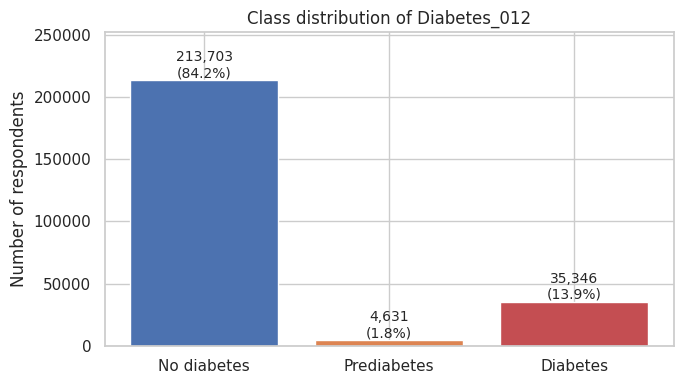

In [10]:
counts = df[TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(CLASS_NAMES, counts.values, color=CLASS_COLORS)
for bar, c, p in zip(bars, counts.values, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{c:,}\n({p:.1f}%)",
            ha="center", va="bottom", fontsize=10)
ax.set_ylabel("Number of respondents")
ax.set_title("Class distribution of Diabetes_012")
ax.set_ylim(0, counts.max() * 1.18)
save_fig("01_class_distribution")

This is the single most important thing about the dataset. In the full data, about 84% of respondents have no diabetes, about 14% have diabetes, and fewer than 2% are in the prediabetes class. A model that predicts "no diabetes" for everyone would already score around 84% accuracy while being completely useless as a screening tool.

Because of this, accuracy will not be my main metric. I will focus on **macro-averaged F1**, **per-class recall** (especially for prediabetes and diabetes, since missing a sick person is the costly mistake in screening), and **one-vs-rest ROC-AUC**. I will also need to deal with the imbalance during training, which I do with class weights and test against oversampling in later experiments.

The prediabetes class is also worth thinking about on its own. Many people with prediabetes have never been told so, which means some of the "no diabetes" answers are probably undiagnosed prediabetes. The label itself is noisy, and I expect this class to be the hardest to predict no matter which model I use.

### 4.2 Continuous features

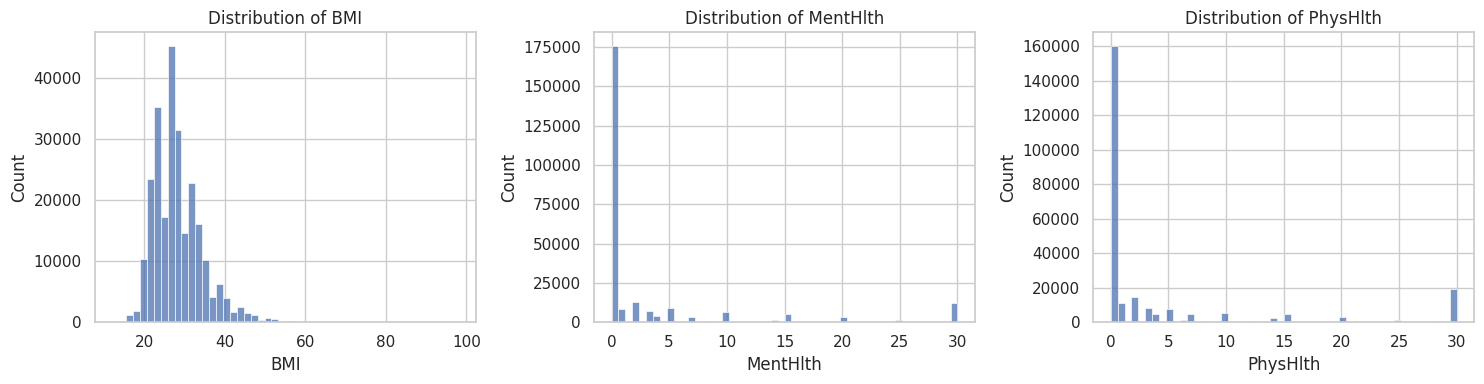

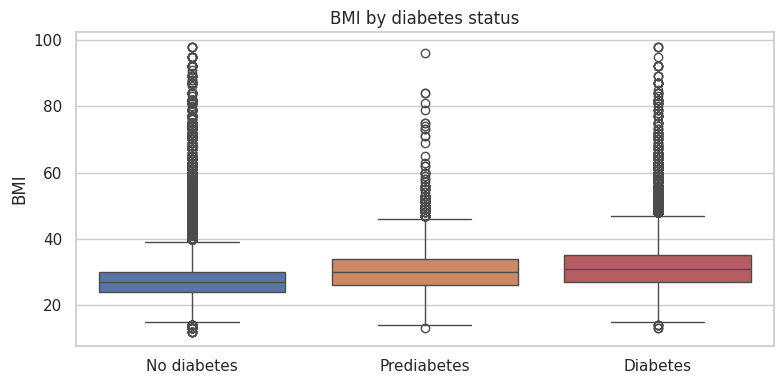

,BMI,MentHlth,PhysHlth
Diabetes_012,,,
No diabetes,27.0,0.0,0.0
Prediabetes,30.0,0.0,0.0
Diabetes,31.0,0.0,1.0


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, CONTINUOUS_COLS):
    sns.histplot(df[col], bins=50, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribution of {col}")
save_fig("02_continuous_distributions")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x=TARGET, y="BMI", hue=TARGET, palette=CLASS_COLORS, legend=False, ax=ax)
ax.set_xticks(range(3), CLASS_NAMES)
ax.set_xlabel("")
ax.set_title("BMI by diabetes status")
save_fig("03_bmi_by_class")

df.groupby(TARGET)[CONTINUOUS_COLS].median().rename(index=dict(enumerate(CLASS_NAMES)))

BMI is right-skewed with a long tail of very high values. Some of these are possible, but values far above 60 in a phone survey where people report their own height and weight are more likely to be mistakes. Instead of deleting those rows, I cap BMI at the 0.5th and 99.5th percentiles of the training set (Section 6), so the rest of each person's answers is kept.

The boxplot shows the pattern I expected: median BMI climbs from the no-diabetes group to the diabetes group, with prediabetes sitting in between. This fits well-established medical evidence that excess weight is one of the strongest risk factors for type 2 diabetes.

`MentHlth` and `PhysHlth` look very different from BMI. Most people report zero bad days, and there are visible spikes at round numbers like 5, 10, 15 and 30. People tend to round when they estimate, and 30 often just means "every day". These are not outliers to remove; they are how people actually answer surveys. I keep the values as they are and add threshold features based on the CDC definition of frequent distress (14 or more days).

### 4.3 Binary risk factors across classes

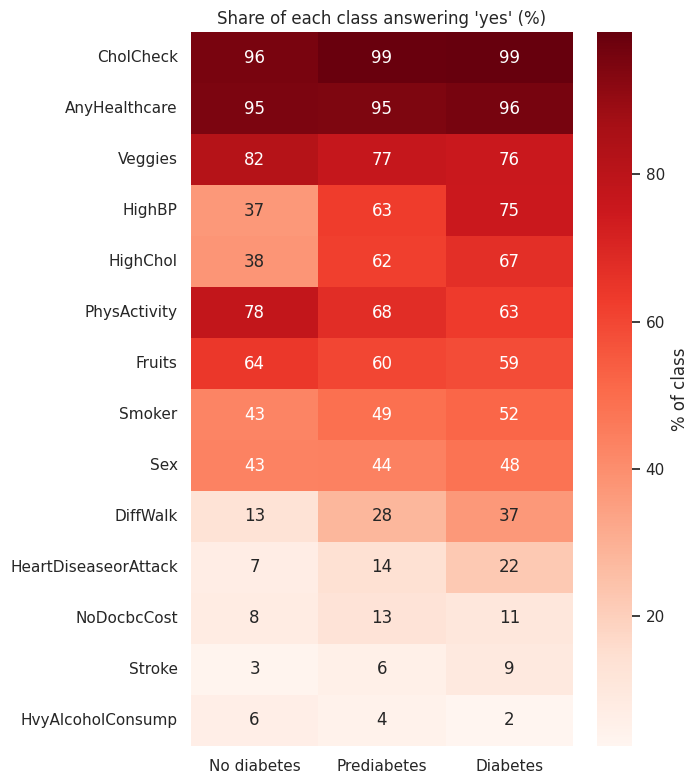

In [12]:
prevalence = df.groupby(TARGET)[BINARY_COLS].mean().T * 100
prevalence.columns = CLASS_NAMES
prevalence = prevalence.sort_values("Diabetes", ascending=False)

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(prevalence, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of class"}, ax=ax)
ax.set_title("Share of each class answering 'yes' (%)")
save_fig("04_binary_prevalence_by_class")

Reading across each row shows which answers separate the classes. High blood pressure, high cholesterol, difficulty walking and heart disease are far more common among people with diabetes than among those without. Lifestyle factors like eating fruit and vegetables differ much less between the groups. In most rows the prediabetes column sits between the other two, which already hints that prediabetes will be confused with both neighbours rather than standing out clearly.

`CholCheck` (had a cholesterol check in the last five years) and `AnyHealthcare` are high for everyone. They will probably carry little information on their own, but I keep them because access to care matters for diagnosis: someone who never sees a doctor cannot be diagnosed with anything.

### 4.4 Ordinal features: age, income and general health

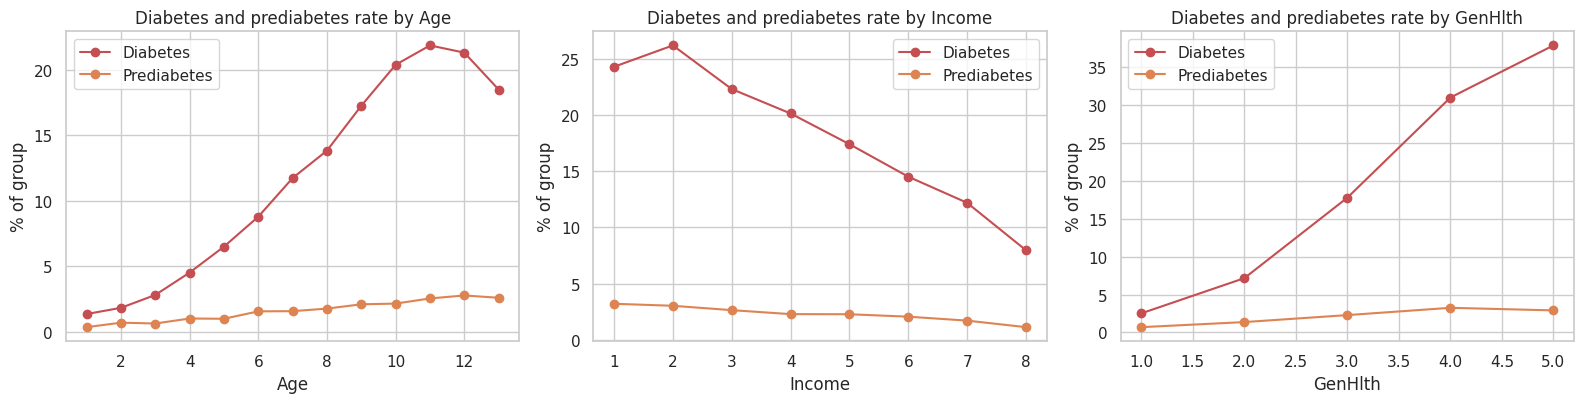

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, ["Age", "Income", "GenHlth"]):
    rates = pd.crosstab(df[col], df[TARGET], normalize="index") * 100
    ax.plot(rates.index, rates[2], marker="o", color=CLASS_COLORS[2], label="Diabetes")
    ax.plot(rates.index, rates[1], marker="o", color=CLASS_COLORS[1], label="Prediabetes")
    ax.set_title(f"Diabetes and prediabetes rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("% of group")
    ax.legend()
save_fig("05_ordinal_gradients")

All three features show clear, mostly steady trends. Diabetes rates rise with age band, fall as income rises, and rise sharply as self-rated general health gets worse. The steady direction of these trends is why I keep them as ordinal numbers instead of one-hot encoding them: the order carries real meaning, and treating them as unrelated categories would throw that away.

The income trend matters for my mission. It shows that diabetes is not only a medical problem but also a social one, linked to food access, health care access and living conditions. That is part of the reason I care about cheap screening tools for lower-income settings like many communities in Rwanda.

### 4.5 Correlations

I use Spearman correlation because most features are binary or ordinal, and Spearman only assumes a monotonic relationship rather than a linear one.

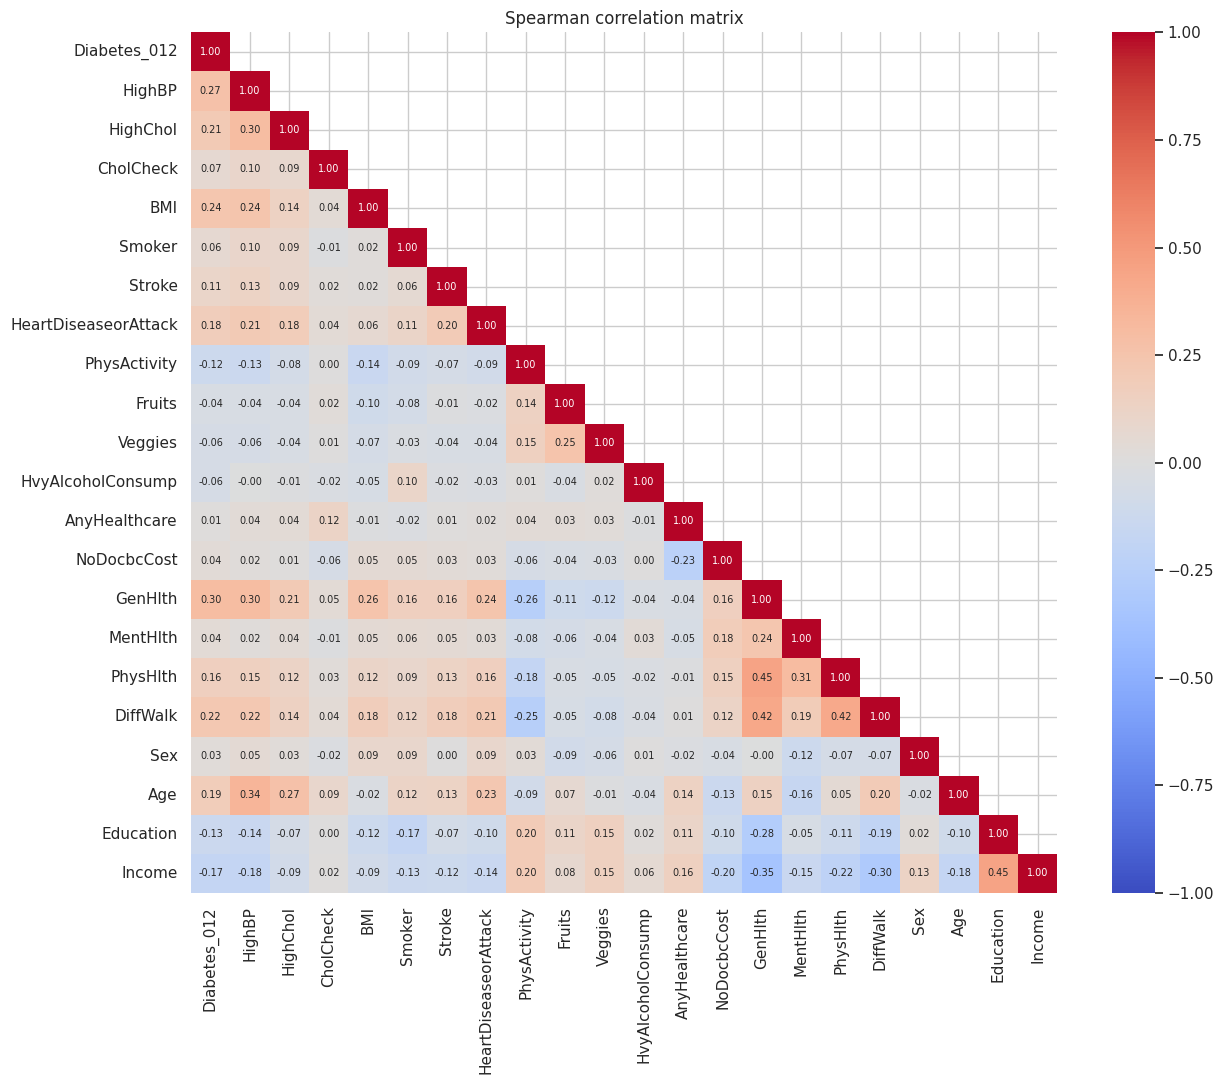

,Spearman r with target
GenHlth,0.297
HighBP,0.272
BMI,0.236
DiffWalk,0.224
HighChol,0.211
Age,0.186
HeartDiseaseorAttack,0.179
Income,-0.173
PhysHlth,0.162
Education,-0.127


In [14]:
corr = df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation matrix")
save_fig("06_correlation_matrix")

target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
target_corr.round(3).to_frame("Spearman r with target")

No single feature is strongly correlated with the target on its own. The strongest ones (general health, high blood pressure, BMI, difficulty walking, age, high cholesterol) are only moderate. That tells me two things. First, the signal is spread across many weak predictors, so models that can combine features and pick up interactions (tree ensembles and neural networks) should have an advantage over a plain linear model. Second, there is a ceiling on how well any model can do with survey answers alone, and I should be honest about that in my discussion.

Some features are correlated with each other, for example `GenHlth`, `PhysHlth` and `DiffWalk`, which all describe physical wellbeing from different angles. None of these pairs are close enough to 1 to be redundant, so I keep all of them and let regularisation handle the overlap.

## 5. Train, validation and test split

I split the data **before** fitting any preprocessing, so nothing about the validation or test sets leaks into training (for example, the BMI caps and the scaler means are learned from the training set only). The split is 70% train, 15% validation and 15% test, stratified on the target so all three sets keep the same class proportions. This matters most for prediabetes, where a non-stratified split could leave the test set with noticeably fewer examples.

The validation set is used for hyperparameter tuning and early stopping. The test set is not touched until the final comparison in Part 4.

In [15]:
X_train_raw, X_val_raw, X_test_raw, y_train, y_val, y_test = split_data(df, seed=SEED)

split_summary = pd.DataFrame({
    name: y.value_counts(normalize=True).sort_index() * 100
    for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]
}).rename(index=dict(enumerate(CLASS_NAMES))).round(2)
split_summary.loc["n rows"] = [len(y_train), len(y_val), len(y_test)]
split_summary

,train,validation,test
Diabetes_012,,,
No diabetes,84.24,84.24,84.24
Prediabetes,1.83,1.82,1.83
Diabetes,13.93,13.93,13.93
n rows,177576.00,38052.00,38052.00


## 6. Preprocessing and feature engineering pipeline

The whole pipeline is defined in `src/preprocessing.py` and has three steps:

1. **Cap BMI** at the 0.5th and 99.5th percentiles learned from the training data.
2. **Engineer new features** from domain knowledge. These include WHO BMI categories, a count of cardiometabolic conditions (high blood pressure, high cholesterol, heart disease, stroke), a lifestyle score, total unhealthy days, CDC "frequent distress" flags, a care-barrier flag (no coverage or could not afford a doctor), a combined high-blood-pressure-and-cholesterol flag, and an age × BMI interaction. The interaction is mainly for the linear model, which cannot discover it by itself.
3. **Scale** the continuous and ordinal columns with `StandardScaler`. Binary columns are left as 0/1.

Scaling matters for logistic regression, SVMs and neural networks, because gradient-based training and distance-based methods are sensitive to feature ranges. Tree models do not need it, but using the same inputs for every model keeps the comparison fair. The `use_engineered` flag lets me run the same models with and without the new features in Part 2, so I can show whether the feature engineering actually helped rather than just assuming it did.

In [16]:
preprocessor = build_preprocessor(use_engineered=True)
X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)
feature_names = get_feature_names(preprocessor)

cap = preprocessor.named_steps["cap_bmi"]
print(f"BMI capped to [{cap.lower_:.1f}, {cap.upper_:.1f}] using training-set percentiles")
print(f"Features after preprocessing: {len(feature_names)} ({len(RAW_FEATURES)} original + "
      f"{len(feature_names) - len(RAW_FEATURES)} engineered)")
print(f"Shapes -> train {X_train.shape}, val {X_val.shape}, test {X_test.shape}")
print(f"Any NaN left: {np.isnan(X_train).any() or np.isnan(X_val).any() or np.isnan(X_test).any()}")

# Sanity check: scaled columns should have mean ~0 and std ~1 on the training set
n_scaled = len(preprocessor.named_steps["scale"].transformers_[0][2])
pd.DataFrame(X_train[:, :n_scaled], columns=feature_names[:n_scaled]).agg(["mean", "std"]).T.round(3)

BMI capped to [17.0, 55.0] using training-set percentiles
Features after preprocessing: 30 (21 original + 9 engineered)
Shapes -> train (177576, 30), val (38052, 30), test (38052, 30)
Any NaN left: False


,mean,std
BMI,-0.0,1.0
MentHlth,0.0,1.0
PhysHlth,0.0,1.0
GenHlth,-0.0,1.0
Age,-0.0,1.0
Education,0.0,1.0
Income,0.0,1.0
BMI_Category,0.0,1.0
CardioRiskCount,0.0,1.0
LifestyleScore,0.0,1.0


### 6.1 Do the engineered features carry signal?

Before using the new features in models, I check them against the target on the **training set only**. If a feature is useful, the share of people with diabetes should change noticeably across its values.

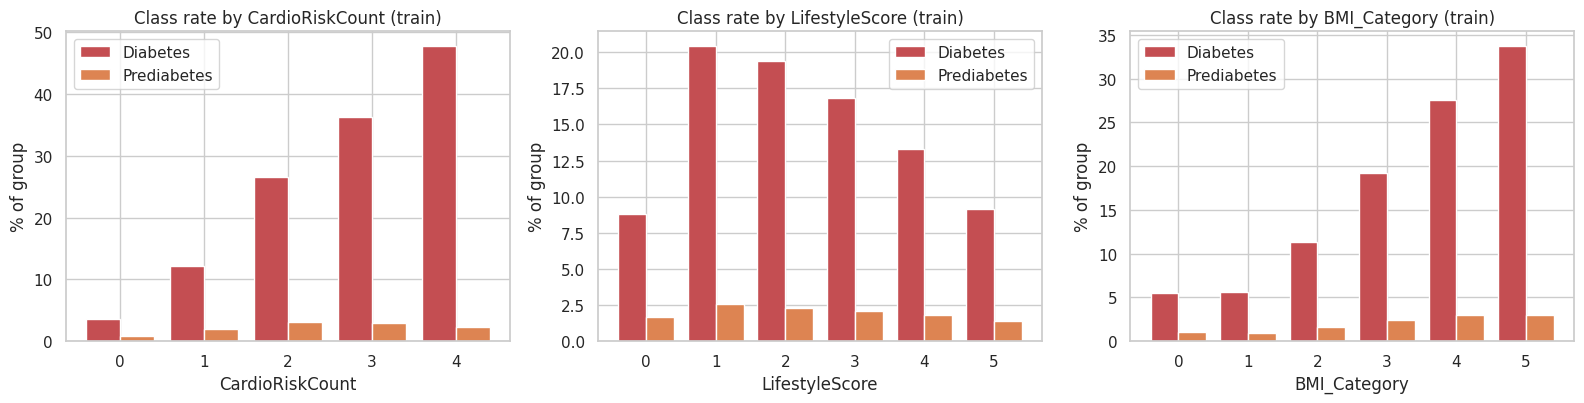

In [17]:
steps = preprocessor.named_steps   # capped + engineered, but not yet scaled
train_fe = steps["engineer"].transform(steps["cap_bmi"].transform(X_train_raw))
train_fe[TARGET] = y_train.values

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, ["CardioRiskCount", "LifestyleScore", "BMI_Category"]):
    rates = pd.crosstab(train_fe[col], train_fe[TARGET], normalize="index") * 100
    ax.bar(rates.index - 0.2, rates[2], width=0.4, color=CLASS_COLORS[2], label="Diabetes")
    ax.bar(rates.index + 0.2, rates[1], width=0.4, color=CLASS_COLORS[1], label="Prediabetes")
    ax.set_title(f"Class rate by {col} (train)")
    ax.set_xlabel(col)
    ax.set_ylabel("% of group")
    ax.legend()
save_fig("07_engineered_features")

`CardioRiskCount` should show the clearest effect: if diabetes rates climb steeply as the number of existing conditions goes from 0 to 4, it confirms that these conditions tend to cluster together and that counting them gives the models a compact summary of overall cardiometabolic risk. `LifestyleScore` is expected to have a weaker, downward trend, in line with the weak individual lifestyle correlations from Section 4.5. `BMI_Category` turns the BMI curve into medically meaningful bands, which is easier to interpret in the report.

These plots only show that each feature relates to the target. Whether they improve the models beyond what the original features already provide is a separate question, and I test that directly in the experiments.

### 6.2 Mutual information ranking

Correlation only captures monotonic relationships. Mutual information (MI) measures any kind of dependency between a feature and the target, so it is a useful second view. I compute it on a 60,000-row stratified sample of the training set to keep it fast, and I tell the estimator which columns are discrete.

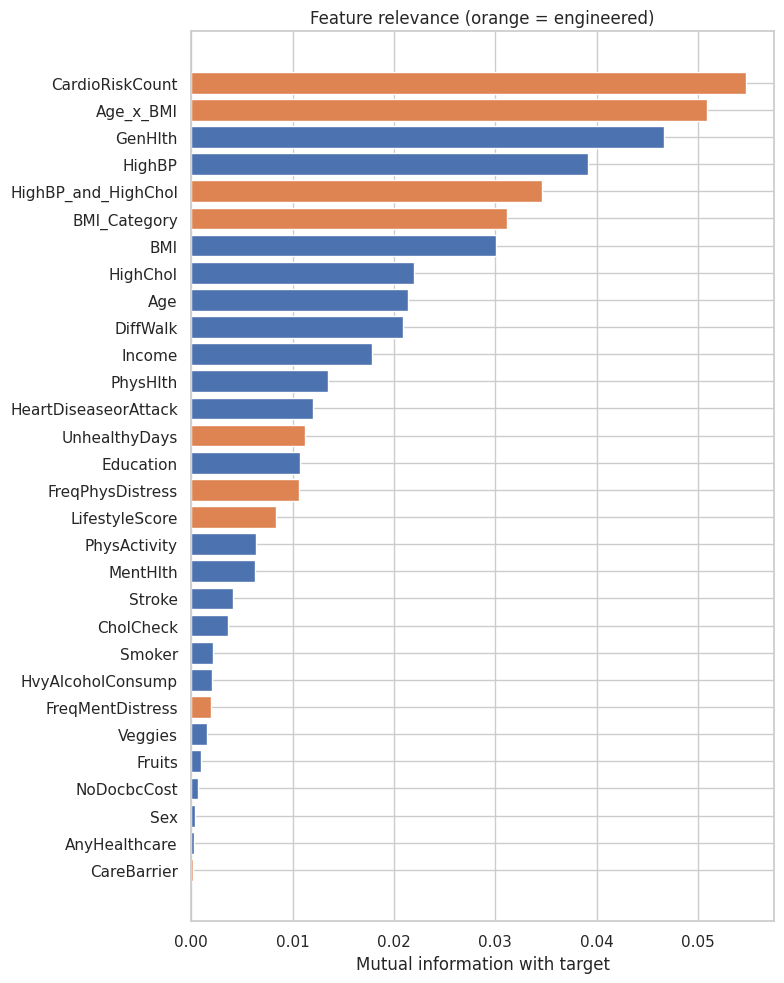

,MI
CardioRiskCount,0.0547
Age_x_BMI,0.0509
GenHlth,0.0466
HighBP,0.0392
HighBP_and_HighChol,0.0346
BMI_Category,0.0312
BMI,0.0301
HighChol,0.0220
Age,0.0214
DiffWalk,0.0208


In [18]:
rng = np.random.RandomState(SEED)
sample_idx = rng.choice(len(X_train), size=min(60_000, len(X_train)), replace=False)
binary_out = set(preprocessor.named_steps["scale"].transformers_[1][2])
discrete_mask = np.array([f in binary_out for f in feature_names])

mi = mutual_info_classif(X_train[sample_idx], y_train.values[sample_idx],
                         discrete_features=discrete_mask, random_state=SEED)
mi_series = pd.Series(mi, index=feature_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 10))
colors = ["#DD8452" if f not in RAW_FEATURES else "#4C72B0" for f in mi_series.index]
ax.barh(mi_series.index, mi_series.values, color=colors)
ax.set_xlabel("Mutual information with target")
ax.set_title("Feature relevance (orange = engineered)")
save_fig("08_mutual_information")

mi_series.sort_values(ascending=False).round(4).head(15).to_frame("MI")

The MI ranking mostly agrees with the correlation analysis: general health, blood pressure, BMI-related features and age sit near the top. Where the engineered features land in this ranking is a first check on whether they add anything new. I do not drop any features based on this ranking alone, because MI looks at one feature at a time and can miss features that only matter in combination. Instead, I use it as the basis for a feature-selection experiment in Part 2, where I compare the full feature set with a reduced top-k set.

## 7. Handling class imbalance

I compute balanced class weights from the training labels. Each class gets a weight inversely proportional to its frequency, so during training a mistake on a prediabetes example costs much more than a mistake on a no-diabetes example. I chose class weighting as my default because it does not create synthetic data and works the same way in scikit-learn and Keras. I compare it against SMOTE oversampling as one of my experiments.

In [19]:
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}

pd.DataFrame({"class": CLASS_NAMES, "train count": np.bincount(y_train),
              "weight": np.round(weights, 3)})

,class,train count,weight
0,No diabetes,149592,0.396
1,Prediabetes,3242,18.258
2,Diabetes,24742,2.392


## 8. Saving the processed data

I save the processed splits, the fitted preprocessing pipeline and the class weights so Parts 2 and 3 start from exactly the same data. The fitted pipeline is also needed later to make predictions on new, raw survey answers.

In [20]:
np.savez_compressed(os.path.join(ART_DIR, "processed_splits.npz"),
                    X_train=X_train, X_val=X_val, X_test=X_test,
                    y_train=y_train.values, y_val=y_val.values, y_test=y_test.values)
joblib.dump(preprocessor, os.path.join(ART_DIR, "preprocessor.joblib"))
with open(os.path.join(ART_DIR, "metadata.json"), "w") as f:
    json.dump({"seed": SEED, "feature_names": feature_names, "class_names": CLASS_NAMES,
               "class_weight": class_weight, "bmi_cap": [cap.lower_, cap.upper_]}, f, indent=2)

print("Saved:", sorted(os.listdir(ART_DIR)))

Saved: ['metadata.json', 'preprocessor.joblib', 'processed_splits.npz']


## Summary of Part 1

The dataset is large and complete, but heavily imbalanced, with prediabetes making up less than 2% of the rows. No single feature is a strong predictor on its own; the signal is spread across many moderate risk factors, led by general health, blood pressure, BMI, mobility and age. I kept duplicate rows because they reflect how real people answer a mostly-yes/no survey, capped extreme BMI values instead of dropping them, and added nine domain-based features. All fitted steps learn only from the training set.

In Part 2 I train and tune the traditional machine learning models, starting from a logistic regression baseline.

---
# Part 2: Traditional Machine Learning

In this part I train and tune three families of scikit-learn models and track every run the same way. I picked these three on purpose because they sit at different points on the bias–variance and interpretability spectrum:

- **Logistic Regression** is a linear model. It is fast and easy to explain (each coefficient says how a feature shifts the odds), but it can only draw straight decision boundaries unless I hand it interaction features.
- **Random Forest** averages many deep decision trees trained on bootstrapped samples. Averaging reduces variance, and the trees can capture interactions automatically.
- **Gradient Boosting** (`HistGradientBoostingClassifier`) builds shallow trees one after another, each fixing the errors of the last. It is usually the strongest model on tabular data like this, and the histogram version is fast enough for 177,000 training rows.

**How I compare runs.** Every model is scored on the same validation set. I use **macro-F1** as the main selection metric because it gives the three classes equal weight, so a model cannot look good by ignoring prediabetes. I also report one-vs-rest ROC-AUC, per-class recall and precision, and the training-set macro-F1 so I can see the gap between training and validation performance, which is a quick check for overfitting.

**How runs are logged.** Each experiment goes through the `ExperimentTracker` in `src/experiments.py`. It writes one row per run to `artifacts/experiment_log.csv` and creates a Weights & Biases run in offline mode under `logs/wandb/`. These logs are what the experiment table in my report is built from, so every number there can be traced back to an actual run.

**The plan.** Each experiment changes one thing from an earlier one, so I can say what caused a change in results:

| ID | What changes | Question it answers |
|---|---|---|
| ML-00 | Majority-class baseline | What does "doing nothing" score? |
| ML-01 | Logistic Regression, original features, no weighting | How far does a plain linear model get? |
| ML-02 | + balanced class weights | Does weighting help the minority classes? |
| ML-03 | + engineered features | Does my feature engineering help a linear model? |
| ML-04 | + tuned C and class-weight strength | Can tuning regularisation and weighting help further? |
| ML-05 | Random Forest, default deep trees | Does a non-linear ensemble beat the linear model? |
| ML-06 | Random Forest, tuned | Does limiting tree depth fix overfitting? |
| ML-07 | Gradient Boosting, default | How does boosting compare to bagging? |
| ML-08 | Gradient Boosting, tuned | What do the best boosting settings achieve? |
| ML-09 | Tuned boosting + SMOTE instead of class weights | Is synthetic oversampling better than weighting? |
| ML-10 | Tuned boosting, original features only | Does feature engineering still matter for a strong model? |
| ML-11 | Tuned boosting, top-15 features by mutual information | Can I simplify the model without losing performance? |

In [21]:
import time
from scipy.stats import loguniform, randint
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, learning_curve
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE

from src.experiments import (
    ExperimentTracker, fit_and_log, FittedClassifier,
    plot_confusion_matrices, plot_roc_curves,
)

tracker = ExperimentTracker(os.path.join(ART_DIR, "experiment_log.csv"), wandb_dir="logs")
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# Version of the data with only the 21 original features, for the feature-engineering comparisons
preprocessor_raw = build_preprocessor(use_engineered=False)
X_train_r = preprocessor_raw.fit_transform(X_train_raw)
X_val_r = preprocessor_raw.transform(X_val_raw)
X_test_r = preprocessor_raw.transform(X_test_raw)

# Stratified sample of the training set used for hyperparameter searches (explained in ML-06)
def stratified_sample_idx(y, n, seed=SEED):
    from sklearn.model_selection import train_test_split
    idx = np.arange(len(y))
    if n >= len(y):
        return idx
    sample, _ = train_test_split(idx, train_size=n, stratify=y, random_state=seed)
    return sample

search_idx = stratified_sample_idx(y_train.values, 60_000)
X_search, y_search = X_train[search_idx], y_train.values[search_idx]

# Everything needed to rebuild and save each model later
fitted = {}
print(f"Engineered features: {X_train.shape[1]} | original features: {X_train_r.shape[1]} | "
      f"search sample: {len(search_idx):,} rows")

Engineered features: 30 | original features: 21 | search sample: 60,000 rows


## 9. Baseline: majority class (ML-00)

Before training anything real, I record what a model that always predicts "no diabetes" scores. Any model that cannot clearly beat this is not learning anything useful.

In [22]:
m, _ = fit_and_log(tracker, "ML-00", DummyClassifier(strategy="most_frequent"),
                   X_train, y_train, X_val, y_val, model_name="Majority class",
                   params={"strategy": "most_frequent"}, features="engineered", imbalance="none",
                   notes="Floor for every other model")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


ML-00 Majority class: val macro-F1 0.3048 | train macro-F1 0.3045 | ROC-AUC 0.5000 | recall prediab 0.000, diab 0.000 | 0.0s


## 10. Logistic Regression (ML-01 to ML-04)

I start with the simplest real model and change one thing at a time. ML-01 uses the original 21 features with no class weighting. ML-02 adds balanced class weights, which I expect to raise recall for prediabetes and diabetes at the cost of more false alarms in the "no diabetes" class. ML-03 swaps in the engineered features. This is where I expect feature engineering to matter most, because a linear model cannot create interactions like age × BMI by itself.

In [23]:
lr_base = dict(max_iter=2000, random_state=SEED)

m01 = fit_and_log(tracker, "ML-01", LogisticRegression(**lr_base), X_train_r, y_train, X_val_r, y_val,
                  model_name="Logistic Regression", params={**lr_base, "C": 1.0, "class_weight": None},
                  features="original", imbalance="none", notes="Linear baseline")

m02 = fit_and_log(tracker, "ML-02", LogisticRegression(class_weight="balanced", **lr_base),
                  X_train_r, y_train, X_val_r, y_val,
                  model_name="Logistic Regression", params={**lr_base, "C": 1.0, "class_weight": "balanced"},
                  features="original", imbalance="class weights", notes="Effect of class weighting")

lr03, m03 = fit_and_log(tracker, "ML-03", LogisticRegression(class_weight="balanced", **lr_base),
                        X_train, y_train, X_val, y_val,
                        model_name="Logistic Regression", params={**lr_base, "C": 1.0, "class_weight": "balanced"},
                        features="engineered", imbalance="class weights", notes="Effect of engineered features")

ML-01 Logistic Regression: val macro-F1 0.3966 | train macro-F1 0.3934 | ROC-AUC 0.7848 | recall prediab 0.000, diab 0.184 | 10.6s
ML-02 Logistic Regression: val macro-F1 0.4273 | train macro-F1 0.4254 | ROC-AUC 0.7726 | recall prediab 0.313, diab 0.594 | 9.6s
ML-03 Logistic Regression: val macro-F1 0.4276 | train macro-F1 0.4266 | ROC-AUC 0.7710 | recall prediab 0.331, diab 0.589 | 7.5s


_Interpretation of ML-01 to ML-03 (write after running): compare ML-01 and ML-02 recall for prediabetes and diabetes, then ML-02 against ML-03 for the effect of the engineered features._

### 10.1 Tuning regularisation and weighting strength (ML-04)

Two settings matter most for logistic regression here. The first is `C`, the inverse of regularisation strength: small values shrink the coefficients more, which helps if the model is fitting noise. The second is how hard I push the class weights. Fully balanced weights make a prediabetes example count around 18 times more than a no-diabetes example, which can swing the model into flagging far too many healthy people. A softer option is to use the square root of the balanced weights. I search over both with 3-fold stratified cross-validation, scored by macro-F1. Logistic regression is fast, so this search uses the full training set.

In [24]:
sqrt_weights = {k: float(np.sqrt(v)) for k, v in class_weight.items()}

lr_grid = GridSearchCV(
    LogisticRegression(**lr_base),
    param_grid={"C": [0.001, 0.01, 0.1, 1, 10], "class_weight": ["balanced", sqrt_weights]},
    scoring="f1_macro", cv=cv3, n_jobs=-1,
)
lr_grid.fit(X_train, y_train)

best_lr_params = lr_grid.best_params_
cw_label = "balanced" if best_lr_params["class_weight"] == "balanced" else "sqrt-balanced"
print(f"Best params: C={best_lr_params['C']}, class_weight={cw_label} | CV macro-F1 {lr_grid.best_score_:.4f}")

lr04, m04 = fit_and_log(tracker, "ML-04", LogisticRegression(**lr_base, **best_lr_params),
                        X_train, y_train, X_val, y_val, model_name="Logistic Regression (tuned)",
                        params={**lr_base, "C": best_lr_params["C"], "class_weight": cw_label,
                                "search": "grid, 10 combos, 3-fold CV"},
                        features="engineered", imbalance=f"class weights ({cw_label})",
                        notes=f"CV macro-F1 {lr_grid.best_score_:.4f}")
fitted["ML-04"] = (lr04, preprocessor, None)

cv_res = pd.DataFrame(lr_grid.cv_results_)
cv_res["class_weight"] = cv_res["param_class_weight"].apply(lambda w: "balanced" if w == "balanced" else "sqrt-balanced")
cv_res.pivot_table(index="param_C", columns="class_weight", values="mean_test_score").round(4)

Best params: C=0.01, class_weight=sqrt-balanced | CV macro-F1 0.4484
ML-04 Logistic Regression (tuned): val macro-F1 0.4494 | train macro-F1 0.4471 | ROC-AUC 0.7827 | recall prediab 0.000, diab 0.489 | 13.4s


class_weight,balanced,sqrt-balanced
param_C,,
0.001,0.4287,0.4477
0.010,0.4269,0.4484
0.100,0.4266,0.4482
1.000,0.4266,0.4483
10.000,0.4265,0.4483


_Interpretation of ML-04 (write after running): which C and weighting won, and whether the CV table shows a clear trend or a flat plateau._

### 10.2 What the linear model learned

One advantage of logistic regression is that its coefficients can be read directly. Because the numeric features are standardised, coefficient sizes are roughly comparable. I plot the coefficients for the diabetes and prediabetes classes.

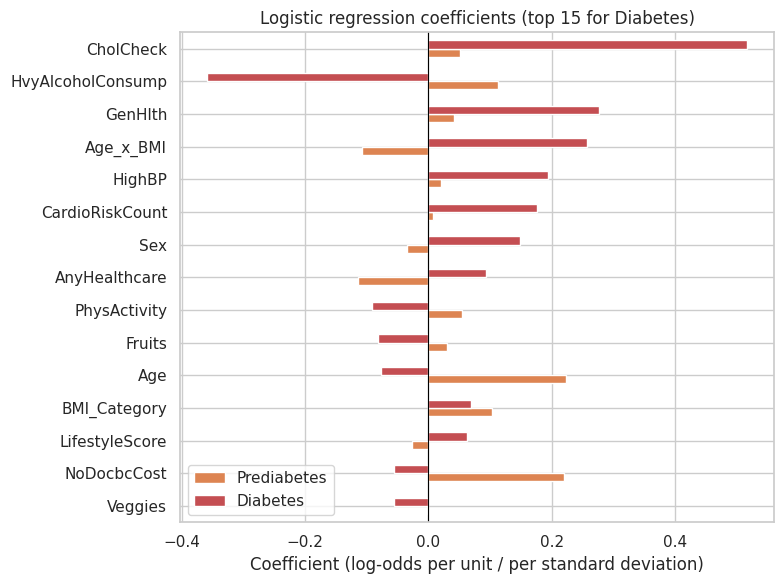

In [25]:
coef = pd.DataFrame(lr04.coef_.T, index=feature_names, columns=CLASS_NAMES)
top = coef["Diabetes"].abs().sort_values(ascending=False).head(15).index

fig, ax = plt.subplots(figsize=(8, 6))
coef.loc[top, ["Prediabetes", "Diabetes"]].iloc[::-1].plot.barh(ax=ax, color=CLASS_COLORS[1:])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Logistic regression coefficients (top 15 for Diabetes)")
ax.set_xlabel("Coefficient (log-odds per unit / per standard deviation)")
save_fig("09_lr_coefficients")

## 11. Random Forest (ML-05 and ML-06)

ML-05 uses fairly default settings: 200 fully grown trees with `balanced_subsample` class weights, which recomputes the weights inside each bootstrap sample. Fully grown trees memorise the training data, so I expect a large gap between training and validation macro-F1. That gap is the classic sign of high variance.

In [26]:
rf05_params = dict(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
rf05, m05 = fit_and_log(tracker, "ML-05", RandomForestClassifier(**rf05_params),
                        X_train, y_train, X_val, y_val, model_name="Random Forest",
                        params={**rf05_params, "max_depth": None, "min_samples_leaf": 1},
                        features="engineered", imbalance="class weights (per bootstrap)",
                        notes="Default deep trees")

ML-05 Random Forest: val macro-F1 0.3842 | train macro-F1 0.9712 | ROC-AUC 0.7434 | recall prediab 0.000, diab 0.161 | 71.0s


_Interpretation of ML-05 (write after running): size of the train/validation gap, and what that says about variance._

### 11.1 Tuning the forest (ML-06)

To control overfitting, I tune the settings that limit how much each tree can memorise: `max_depth`, `min_samples_leaf` (the minimum number of people a leaf must contain) and `max_features` (how many features each split can consider). I use a randomised search with 12 combinations and 3-fold cross-validation.

Running this search on all 177,000 rows would take a long time on Colab, since every combination trains a full forest three times. So I run the search on a stratified 60,000-row sample, which keeps the same class proportions, and then retrain the winning settings on the full training set. The relative ranking of hyperparameters is usually stable at this sample size, and I accept the small risk that the best settings for 60,000 rows are not exactly the best for 177,000.

In [27]:
rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=1, random_state=SEED),
    param_distributions={
        "n_estimators": [200, 300],
        "max_depth": [8, 12, 16, 20, None],
        "min_samples_leaf": [1, 5, 10, 25, 50],
        "max_features": ["sqrt", 0.3, 0.5],
        "class_weight": ["balanced", "balanced_subsample"],
    },
    n_iter=12, scoring="f1_macro", cv=cv3, n_jobs=-1, random_state=SEED,
)
start = time.time()
rf_search.fit(X_search, y_search)
print(f"Search took {time.time() - start:.0f}s | best CV macro-F1 {rf_search.best_score_:.4f}")
print("Best params:", rf_search.best_params_)

rf06_params = {**rf_search.best_params_, "n_jobs": -1, "random_state": SEED}
rf06, m06 = fit_and_log(tracker, "ML-06", RandomForestClassifier(**rf06_params),
                        X_train, y_train, X_val, y_val, model_name="Random Forest (tuned)",
                        params={**rf06_params, "search": "random, 12 combos, 3-fold CV, 60k sample"},
                        features="engineered", imbalance="class weights",
                        notes=f"CV macro-F1 {rf_search.best_score_:.4f}")
fitted["ML-06"] = (rf06, preprocessor, None)

pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_score")[
    ["param_max_depth", "param_min_samples_leaf", "param_max_features", "param_class_weight",
     "param_n_estimators", "mean_test_score", "mean_fit_time"]].head(6).round(4)

Search took 602s | best CV macro-F1 0.4508
Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 16, 'class_weight': 'balanced_subsample'}
ML-06 Random Forest (tuned): val macro-F1 0.4430 | train macro-F1 0.7383 | ROC-AUC 0.7547 | recall prediab 0.013, diab 0.663 | 150.2s


,param_max_depth,param_min_samples_leaf,param_max_features,param_class_weight,param_n_estimators,mean_test_score,mean_fit_time
4,16,5,0.5,balanced_subsample,300,0.4508,54.9776
0,12,5,0.5,balanced_subsample,300,0.4443,46.7544
10,16,25,0.5,balanced_subsample,300,0.4374,43.5032
1,20,25,0.5,balanced_subsample,200,0.4359,29.4001
6,12,25,0.3,balanced_subsample,200,0.4357,20.8887
5,16,25,0.3,balanced_subsample,200,0.4354,20.6248


_Interpretation of ML-06 (write after running): did limiting depth/leaf size shrink the train/validation gap, and did validation macro-F1 go up?_

## 12. Gradient Boosting (ML-07 and ML-08)

Boosting works the opposite way from a random forest. Instead of averaging many deep, high-variance trees, it adds many shallow, high-bias trees one at a time, each one correcting what the previous trees got wrong. The learning rate controls how big each correction is. `HistGradientBoostingClassifier` bins each feature into at most 255 values before training, which makes it much faster than the classic implementation on a dataset this size. It also stops early by itself when a held-out part of the training data stops improving, which protects against adding too many trees.

In [28]:
hgb07_params = dict(class_weight="balanced", random_state=SEED)
hgb07, m07 = fit_and_log(tracker, "ML-07", HistGradientBoostingClassifier(**hgb07_params),
                         X_train, y_train, X_val, y_val, model_name="Gradient Boosting",
                         params={**hgb07_params, "learning_rate": 0.1, "max_leaf_nodes": 31,
                                 "early_stopping": "auto"},
                         features="engineered", imbalance="class weights", notes="Default boosting")
print(f"Boosting iterations used: {hgb07.n_iter_}")

ML-07 Gradient Boosting: val macro-F1 0.4176 | train macro-F1 0.4335 | ROC-AUC 0.7611 | recall prediab 0.281, diab 0.639 | 6.0s
Boosting iterations used: 39


### 12.1 Tuning boosting (ML-08)

I search over the learning rate, tree size (`max_leaf_nodes`, `max_depth`), `min_samples_leaf` and L2 regularisation. A smaller learning rate usually generalises better but needs more trees, so I allow up to 500 iterations and let early stopping decide where to stop. As with the forest, the search runs on the 60,000-row sample with 16 combinations and 3-fold CV.

In [29]:
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(max_iter=500, early_stopping=True, n_iter_no_change=20,
                                   class_weight="balanced", random_state=SEED),
    param_distributions={
        "learning_rate": loguniform(0.02, 0.3),
        "max_leaf_nodes": [15, 31, 63],
        "max_depth": [None, 4, 6, 10],
        "min_samples_leaf": [20, 50, 100, 200],
        "l2_regularization": [0.0, 0.1, 1.0, 5.0],
    },
    n_iter=16, scoring="f1_macro", cv=cv3, n_jobs=-1, random_state=SEED,
)
start = time.time()
hgb_search.fit(X_search, y_search)
print(f"Search took {time.time() - start:.0f}s | best CV macro-F1 {hgb_search.best_score_:.4f}")
print("Best params:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in hgb_search.best_params_.items()})

hgb_best = {**hgb_search.best_params_, "max_iter": 500, "early_stopping": True,
            "n_iter_no_change": 20, "random_state": SEED}
hgb08, m08 = fit_and_log(tracker, "ML-08", HistGradientBoostingClassifier(class_weight="balanced", **hgb_best),
                         X_train, y_train, X_val, y_val, model_name="Gradient Boosting (tuned)",
                         params={**hgb_best, "class_weight": "balanced",
                                 "search": "random, 16 combos, 3-fold CV, 60k sample"},
                         features="engineered", imbalance="class weights",
                         notes=f"CV macro-F1 {hgb_search.best_score_:.4f}")
fitted["ML-08"] = (hgb08, preprocessor, None)
print(f"Boosting iterations used: {hgb08.n_iter_}")

Search took 78s | best CV macro-F1 0.4264
Best params: {'l2_regularization': 1.0, 'learning_rate': np.float64(0.0694), 'max_depth': None, 'max_leaf_nodes': 63, 'min_samples_leaf': 50}
ML-08 Gradient Boosting (tuned): val macro-F1 0.4189 | train macro-F1 0.4479 | ROC-AUC 0.7583 | recall prediab 0.245, diab 0.647 | 9.2s
Boosting iterations used: 43


_Interpretation of ML-07 and ML-08 (write after running)._

## 13. Imbalance strategy and feature set (ML-09 to ML-11)

These three runs keep the tuned boosting settings fixed and change one thing each.

**ML-09: SMOTE instead of class weights.** SMOTE creates new synthetic minority-class rows by interpolating between real neighbouring rows. It is applied to the training set only, never to validation or test data, because synthetic rows in the evaluation sets would make the results meaningless. One concern is that most of my features are binary, so interpolating between two people can produce in-between values like "0.4 smoker" that no real respondent could give. This run tests whether SMOTE helps despite that.

**ML-10: original features only.** Tree ensembles can find interactions on their own, so the engineered features may matter less here than for logistic regression. Comparing ML-10 with ML-08 tells me whether they still add anything.

**ML-11: top 15 features by mutual information.** If a smaller model performs about as well, it would be cheaper to deploy and would need fewer survey questions, which matters for a real screening tool.

In [30]:
start = time.time()
X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
print(f"SMOTE took {time.time() - start:.0f}s | training rows {len(y_train):,} -> {len(y_smote):,}")
print("Class counts after SMOTE:", np.bincount(y_smote))

hgb09, m09 = fit_and_log(tracker, "ML-09", HistGradientBoostingClassifier(**hgb_best),
                         X_smote, y_smote, X_val, y_val, model_name="Gradient Boosting (tuned)",
                         params={**hgb_best, "class_weight": None, "smote_k_neighbors": 5},
                         features="engineered", imbalance="SMOTE (train only)",
                         notes="SMOTE vs class weights")
fitted["ML-09"] = (hgb09, preprocessor, None)

SMOTE took 6s | training rows 177,576 -> 448,776
Class counts after SMOTE: [149592 149592 149592]
ML-09 Gradient Boosting (tuned): val macro-F1 0.4115 | train macro-F1 0.9256 | ROC-AUC 0.7409 | recall prediab 0.000, diab 0.230 | 183.0s


In [31]:
hgb10, m10 = fit_and_log(tracker, "ML-10", HistGradientBoostingClassifier(class_weight="balanced", **hgb_best),
                         X_train_r, y_train, X_val_r, y_val, model_name="Gradient Boosting (tuned)",
                         params={**hgb_best, "class_weight": "balanced"},
                         features="original", imbalance="class weights",
                         notes="Engineered vs original features")
fitted["ML-10"] = (hgb10, preprocessor_raw, None)

top_k = 15
top_features = list(mi_series.sort_values(ascending=False).index[:top_k])
top_idx = [feature_names.index(f) for f in top_features]
print(f"Top {top_k} features by MI:", top_features)

hgb11, m11 = fit_and_log(tracker, "ML-11", HistGradientBoostingClassifier(class_weight="balanced", **hgb_best),
                         X_train[:, top_idx], y_train, X_val[:, top_idx], y_val,
                         model_name="Gradient Boosting (tuned)",
                         params={**hgb_best, "class_weight": "balanced", "top_k": top_k},
                         features=f"top-{top_k} by MI", imbalance="class weights",
                         notes="Feature selection")
fitted["ML-11"] = (hgb11, preprocessor, top_idx)

ML-10 Gradient Boosting (tuned): val macro-F1 0.4182 | train macro-F1 0.4450 | ROC-AUC 0.7600 | recall prediab 0.264, diab 0.640 | 7.2s
Top 15 features by MI: ['CardioRiskCount', 'Age_x_BMI', 'GenHlth', 'HighBP', 'HighBP_and_HighChol', 'BMI_Category', 'BMI', 'HighChol', 'Age', 'DiffWalk', 'Income', 'PhysHlth', 'HeartDiseaseorAttack', 'UnhealthyDays', 'Education']
ML-11 Gradient Boosting (tuned): val macro-F1 0.4169 | train macro-F1 0.4430 | ROC-AUC 0.7566 | recall prediab 0.255, diab 0.627 | 6.6s


_Interpretation of ML-09 to ML-11 (write after running)._

## 14. Results of all traditional ML experiments

This table is generated from the tracker, so it matches the CSV and the W&B logs exactly.

In [32]:
cols = ["exp_id", "model", "features", "imbalance", "train_macro_f1", "macro_f1", "balanced_accuracy",
        "roc_auc_macro", "pr_auc_macro", "recall_no_diab", "recall_prediab", "recall_diab",
        "precision_diab", "accuracy", "train_time_s"]
ml_results = tracker.table(cols)
ml_results.round(4)

,exp_id,model,features,imbalance,train_macro_f1,macro_f1,balanced_accuracy,roc_auc_macro,pr_auc_macro,recall_no_diab,recall_prediab,recall_diab,precision_diab,accuracy,train_time_s
0,ML-00,Majority class,engineered,none,0.3045,0.3048,0.3333,0.5000,0.3333,1.0000,0.0000,0.0000,0.0000,0.8424,0.0
1,ML-01,Logistic Regression,original,none,0.3934,0.3966,0.3866,0.7848,0.4697,0.9761,0.0000,0.1837,0.5349,0.8479,10.6
2,ML-02,Logistic Regression,original,class weights,0.4254,0.4273,0.5219,0.7726,0.4667,0.6593,0.3127,0.5937,0.3586,0.6438,9.6
3,ML-03,Logistic Regression,engineered,class weights,0.4266,0.4276,0.5251,0.7710,0.4679,0.6549,0.3314,0.5890,0.3644,0.6398,7.5
4,ML-04,Logistic Regression (tuned),engineered,class weights (sqrt-balanced),0.4471,0.4494,0.4613,0.7827,0.4707,0.8944,0.0000,0.4894,0.4177,0.8216,13.4
5,ML-05,Random Forest,engineered,class weights (per bootstrap),0.9712,0.3842,0.3770,0.7434,0.4444,0.9697,0.0000,0.1613,0.4785,0.8394,71.0
6,ML-06,Random Forest (tuned),engineered,class weights,0.7383,0.4430,0.4903,0.7547,0.4642,0.7953,0.0130,0.6628,0.3497,0.7625,150.2
7,ML-07,Gradient Boosting,engineered,class weights,0.4335,0.4176,0.5148,0.7611,0.4644,0.6248,0.2810,0.6386,0.3448,0.6204,6.0
8,ML-08,Gradient Boosting (tuned),engineered,class weights,0.4479,0.4189,0.5098,0.7583,0.4633,0.6371,0.2450,0.6473,0.3393,0.6314,9.2
9,ML-09,Gradient Boosting (tuned),engineered,SMOTE (train only),0.9256,0.4115,0.3993,0.7409,0.4650,0.9681,0.0000,0.2299,0.5192,0.8476,183.0


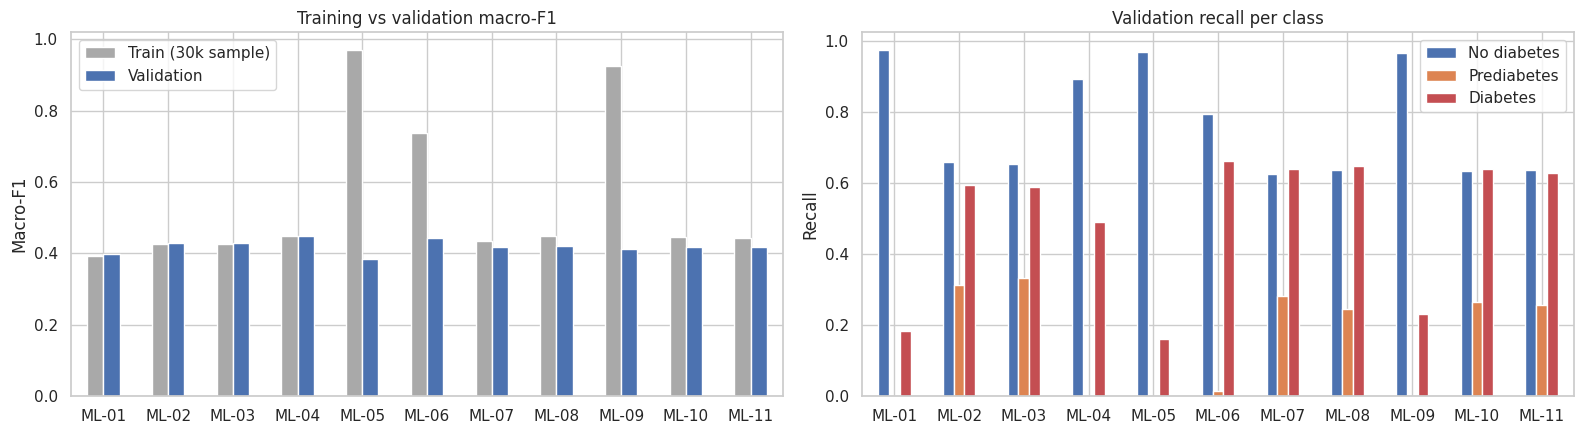

In [33]:
plot_df = ml_results[ml_results["exp_id"] != "ML-00"].set_index("exp_id")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
plot_df[["train_macro_f1", "macro_f1"]].plot.bar(ax=axes[0], color=["#A9A9A9", "#4C72B0"])
axes[0].set_title("Training vs validation macro-F1")
axes[0].set_ylabel("Macro-F1")
axes[0].legend(["Train (30k sample)", "Validation"])

plot_df[["recall_no_diab", "recall_prediab", "recall_diab"]].plot.bar(ax=axes[1], color=CLASS_COLORS)
axes[1].set_title("Validation recall per class")
axes[1].set_ylabel("Recall")
axes[1].legend(CLASS_NAMES)
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
save_fig("10_ml_experiment_comparison")

_Interpretation of the comparison (write after running)._

## 15. Closer look at the best traditional model

I pick the run with the highest validation macro-F1 among the saved candidates and look at it in detail: its confusion matrix, ROC curves, learning curve and which features it relies on. The test set is still untouched; it is only used in Part 4.

Best traditional model: ML-04


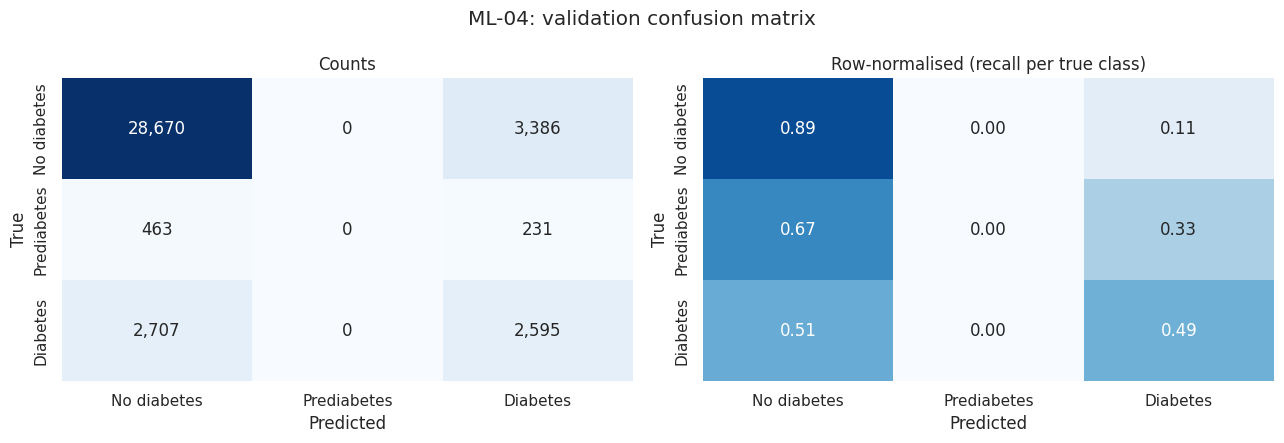

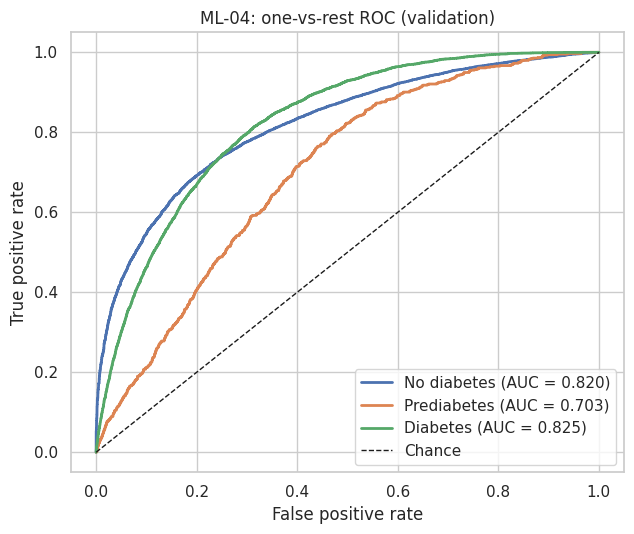

In [34]:
candidates = ml_results[ml_results["exp_id"].isin(fitted.keys())]
best_ml_id = candidates.sort_values("macro_f1", ascending=False).iloc[0]["exp_id"]
best_ml_model, best_ml_prep, best_ml_cols = fitted[best_ml_id]
print(f"Best traditional model: {best_ml_id}")

def select(X, cols):
    return X if cols is None else X[:, cols]

X_val_best = select(best_ml_prep.transform(X_val_raw), best_ml_cols)
val_proba_ml = best_ml_model.predict_proba(X_val_best)
val_pred_ml = val_proba_ml.argmax(axis=1)

cm_ml = plot_confusion_matrices(y_val, val_pred_ml, CLASS_NAMES,
                                f"{best_ml_id}: validation confusion matrix",
                                os.path.join(FIG_DIR, "11_ml_best_confusion_matrix.png"))
plot_roc_curves(y_val, val_proba_ml, CLASS_NAMES, f"{best_ml_id}: one-vs-rest ROC (validation)",
                os.path.join(FIG_DIR, "12_ml_best_roc.png"))

_Interpretation of the confusion matrix and ROC curves (write after running): which classes get confused with which, and why the ROC-AUC can look good while prediabetes recall/precision is weak._

### 15.1 Learning curve

A learning curve shows how training and cross-validated macro-F1 change as the model sees more data. If the two lines are far apart, the model has high variance and would benefit from more data or stronger regularisation. If both lines are low and close together, the model has high bias and needs more capacity or better features. To keep this affordable, I compute it on the 60,000-row search sample with 3-fold CV.

Learning curve took 6s


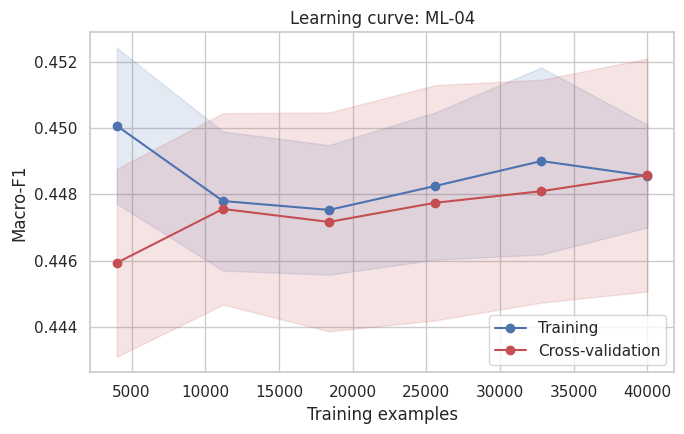

In [35]:
X_lc = select(best_ml_prep.transform(X_train_raw), best_ml_cols)[search_idx]
start = time.time()
sizes, train_scores, val_scores = learning_curve(
    best_ml_model, X_lc, y_search, train_sizes=np.linspace(0.1, 1.0, 6),
    cv=cv3, scoring="f1_macro", n_jobs=-1, shuffle=True, random_state=SEED,
)
print(f"Learning curve took {time.time() - start:.0f}s")

fig, ax = plt.subplots(figsize=(7, 4.5))
for scores, label, color in [(train_scores, "Training", "#4C72B0"), (val_scores, "Cross-validation", "#C44E52")]:
    mean, std = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, mean, marker="o", color=color, label=label)
    ax.fill_between(sizes, mean - std, mean + std, color=color, alpha=0.15)
ax.set_xlabel("Training examples")
ax.set_ylabel("Macro-F1")
ax.set_title(f"Learning curve: {best_ml_id}")
ax.legend()
save_fig("13_ml_learning_curve")

_Interpretation of the learning curve (write after running)._

### 15.2 Which features matter?

I use permutation importance on a 20,000-row validation sample: each feature is shuffled in turn and I measure how much macro-F1 drops. A big drop means the model depends on that feature. Unlike the built-in tree importances, this works the same way for any model and is measured on data the model was not trained on.

Permutation importance took 2s


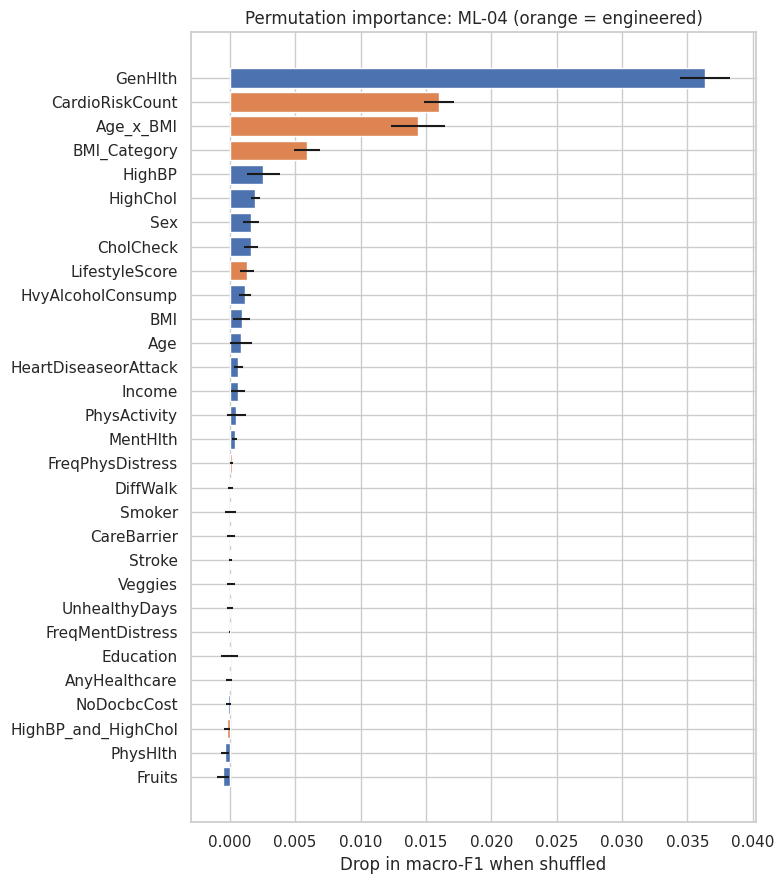

In [36]:
imp_idx = stratified_sample_idx(y_val.values, 20_000)
best_feature_names = feature_names if best_ml_prep is preprocessor else get_feature_names(best_ml_prep)
if best_ml_cols is not None:
    best_feature_names = [best_feature_names[i] for i in best_ml_cols]

start = time.time()
perm = permutation_importance(best_ml_model, X_val_best[imp_idx], y_val.values[imp_idx],
                              scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
print(f"Permutation importance took {time.time() - start:.0f}s")

perm_s = pd.Series(perm.importances_mean, index=best_feature_names).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(perm_s.index, perm_s.values,
        xerr=pd.Series(perm.importances_std, index=best_feature_names)[perm_s.index].values,
        color=["#DD8452" if f not in RAW_FEATURES else "#4C72B0" for f in perm_s.index])
ax.set_xlabel("Drop in macro-F1 when shuffled")
ax.set_title(f"Permutation importance: {best_ml_id} (orange = engineered)")
save_fig("14_ml_permutation_importance")

_Interpretation of feature importance (write after running)._

### 15.3 Saving the best traditional model

I save the best model together with its fitted preprocessing pipeline, so the file takes raw survey answers and returns predictions. This `.joblib` file goes in the Google Drive folder. Loading it requires the `src/` folder to be importable.

In [37]:
best_ml_bundle = FittedClassifier(best_ml_prep, best_ml_model, best_ml_cols, CLASS_NAMES)
ml_model_path = os.path.join(ART_DIR, f"best_traditional_model_{best_ml_id}.joblib")
joblib.dump(best_ml_bundle, ml_model_path)

# Quick check that the saved file works on raw rows
reloaded = joblib.load(ml_model_path)
assert np.allclose(reloaded.predict_proba(X_val_raw.iloc[:100]), val_proba_ml[:100])
print(f"Saved and verified: {ml_model_path} ({os.path.getsize(ml_model_path) / 1e6:.1f} MB)")

Saved and verified: artifacts/best_traditional_model_ML-04.joblib (0.0 MB)


## Summary of Part 2

_Write after running: best model and score, the effect of class weighting, feature engineering, tuning and SMOTE, and the main trade-off between interpretability (logistic regression) and performance (boosting)._

In Part 3 I build neural networks in Keras with a `tf.data` input pipeline and compare them against the best model from this part.

---
# Part 3: Deep Learning with TensorFlow/Keras

This data is a table of survey answers. There are no images, sequences or text, so convolutional or recurrent layers would not make sense. The natural deep learning model is a **multilayer perceptron (MLP)**: stacked fully connected layers that can learn non-linear combinations of the features. Research on tabular data has repeatedly found that well-tuned gradient boosting is hard to beat with neural networks, so one honest question for this part is whether a neural network can catch up with the best model from Part 2, and at what cost.

**Input pipeline.** All data goes through a `tf.data` pipeline (`make_dataset` in `src/deep_learning.py`). It turns the class weights into per-example sample weights, caches the data in memory, reshuffles the training set every epoch with a fixed seed, batches it, and prefetches the next batch while the current one trains.

**Training setup.** Every network uses sparse categorical cross-entropy and a softmax output over the three classes. A custom callback computes training and validation macro-F1 after each epoch, because loss on its own does not show how the small classes are doing. Early stopping watches validation macro-F1 with a patience of 8 epochs and restores the weights from the best epoch. Every run is logged to TensorBoard (`logs/tensorboard/<exp_id>`) and to the same experiment tracker as Part 2.

**The plan.** Again, each run changes one thing:

| ID | What changes | Question it answers |
|---|---|---|
| DL-01 | Small MLP (64, 32), no weighting | Baseline network |
| DL-02 | + balanced class weights | Same question as ML-02, for a network |
| DL-03 | Bigger MLP (256, 128, 64), no regularisation | Does more capacity help, or just overfit? |
| DL-04 | + dropout 0.3 and batch normalisation | Does regularisation fix the overfitting? |
| DL-05 | + L2 weight decay and learning-rate reduction | Do these add anything on top? |
| DL-06 | DL-05 with learning rate 0.01 | What happens when the learning rate is too high? |
| DL-07 | DL-05 with SGD + momentum instead of Adam | Does the optimiser matter? |
| DL-08 | Wide & Deep network (Functional API) | Does adding a linear shortcut help? |
| DL-09 | Best of DL-05/DL-08 with softer class weights | Can I trade some recall for better precision? |

In [38]:
import tensorflow as tf
from tensorflow import keras
from src.deep_learning import make_dataset, build_mlp, build_wide_and_deep, run_keras_experiment

keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()   # same results on every run
except Exception as err:
    print("Op determinism not available:", err)

print(f"TensorFlow {tf.__version__} | GPUs: {tf.config.list_physical_devices('GPU') or 'none (CPU is fine for this data)'}")

INPUT_DIM = X_train.shape[1]
TB_ROOT = os.path.join("logs", "tensorboard")
dl_runs = {}   # exp_id -> (model, history)

# Quick look at one batch from the pipeline
sample_ds = make_dataset(X_train, y_train, class_weight, batch_size=512, shuffle=True, seed=SEED)
xb, yb, wb = next(iter(sample_ds))
print(f"Batch shapes -> features {xb.shape}, labels {yb.shape}, weights {wb.shape}")
print("Weights in this batch by class:", {int(c): float(wb[yb == c][0]) for c in np.unique(yb.numpy())})

TensorFlow 2.21.0 | GPUs: none (CPU is fine for this data)
Batch shapes -> features (512, 30), labels (512,), weights (512,)
Weights in this batch by class: {0: 0.39568960666656494, 1: 18.25786590576172, 2: 2.392369270324707}


## 16. Baseline networks (DL-01 and DL-02)

I start small: two hidden layers with 64 and 32 units and ReLU activations, trained with Adam at its default learning rate of 0.001 and a batch size of 512. DL-01 uses no weighting, and DL-02 adds the same balanced class weights as Part 2.

In [39]:
common = dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, tb_root=TB_ROOT, seed=SEED)

dl_runs["DL-01"] = run_keras_experiment(
    tracker, "DL-01", lambda: build_mlp(INPUT_DIM, hidden=(64, 32), name="mlp_small"), **common,
    model_name="MLP (64-32)", params={"api": "Sequential", "hidden": [64, 32], "dropout": 0,
                                       "batch_norm": False, "l2": 0},
    imbalance="none", notes="Baseline network")[:2]

dl_runs["DL-02"] = run_keras_experiment(
    tracker, "DL-02", lambda: build_mlp(INPUT_DIM, hidden=(64, 32), name="mlp_small"), **common,
    model_name="MLP (64-32)", params={"api": "Sequential", "hidden": [64, 32], "dropout": 0,
                                       "batch_norm": False, "l2": 0},
    class_weights=class_weight, imbalance="class weights", notes="Effect of class weighting")[:2]

DL-01 MLP (64-32): val macro-F1 0.4233 | train macro-F1 0.4209 | ROC-AUC 0.7856 | recall prediab 0.000, diab 0.267 | best epoch 5/13 | 31s
DL-02 MLP (64-32): val macro-F1 0.4260 | train macro-F1 0.4283 | ROC-AUC 0.7676 | recall prediab 0.305, diab 0.612 | best epoch 7/15 | 39s


_Interpretation of DL-01 and DL-02 (write after running)._

## 17. Capacity and regularisation (DL-03 to DL-05)

DL-03 makes the network much bigger (256, 128 and 64 units) with no regularisation at all. With roughly 50,000 trainable parameters and a fairly noisy target, I expect it to start memorising the training data, which should show up as training macro-F1 climbing while validation macro-F1 stalls or falls.

DL-04 adds two kinds of regularisation. **Dropout** (rate 0.3) randomly switches off 30% of the units during each training step, so the network cannot rely on any single unit and has to learn more robust patterns. **Batch normalisation** rescales each layer's inputs during training, which makes optimisation smoother and adds a small regularising effect.

DL-05 adds **L2 weight decay** (λ = 0.0001), which penalises large weights, and **ReduceLROnPlateau**, which halves the learning rate when validation loss stops improving for 3 epochs, so the optimiser can settle into a better minimum.

In [40]:
dl_runs["DL-03"] = run_keras_experiment(
    tracker, "DL-03", lambda: build_mlp(INPUT_DIM, hidden=(256, 128, 64), name="mlp_large"), **common,
    model_name="MLP (256-128-64)", params={"api": "Sequential", "hidden": [256, 128, 64], "dropout": 0,
                                            "batch_norm": False, "l2": 0},
    class_weights=class_weight, imbalance="class weights", notes="More capacity, no regularisation")[:2]

dl_runs["DL-04"] = run_keras_experiment(
    tracker, "DL-04", lambda: build_mlp(INPUT_DIM, hidden=(256, 128, 64), dropout=0.3, batch_norm=True,
                                        name="mlp_large_reg"), **common,
    model_name="MLP (256-128-64) + dropout/BN",
    params={"api": "Sequential", "hidden": [256, 128, 64], "dropout": 0.3, "batch_norm": True, "l2": 0},
    class_weights=class_weight, imbalance="class weights", notes="Dropout + batch norm")[:2]

reg_cfg = dict(hidden=(256, 128, 64), dropout=0.3, batch_norm=True, l2=1e-4)
reg_params = {"api": "Sequential", "hidden": [256, 128, 64], "dropout": 0.3, "batch_norm": True, "l2": 1e-4}

dl_runs["DL-05"] = run_keras_experiment(
    tracker, "DL-05", lambda: build_mlp(INPUT_DIM, name="mlp_large_l2", **reg_cfg), **common,
    model_name="MLP (256-128-64) + dropout/BN/L2", params=reg_params,
    class_weights=class_weight, imbalance="class weights", reduce_lr=True,
    notes="+ L2 and ReduceLROnPlateau")[:2]

DL-03 MLP (256-128-64): val macro-F1 0.4346 | train macro-F1 0.4379 | ROC-AUC 0.7700 | recall prediab 0.297, diab 0.605 | best epoch 7/15 | 60s
DL-04 MLP (256-128-64) + dropout/BN: val macro-F1 0.4201 | train macro-F1 0.4202 | ROC-AUC 0.7758 | recall prediab 0.275, diab 0.677 | best epoch 12/20 | 131s
DL-05 MLP (256-128-64) + dropout/BN/L2: val macro-F1 0.4191 | train macro-F1 0.4170 | ROC-AUC 0.7721 | recall prediab 0.352, diab 0.636 | best epoch 14/22 | 149s


_Interpretation of DL-03 to DL-05 (write after running): compare the train/validation gap across the three runs, using the learning curves in Section 19._

## 18. Optimisation and architecture (DL-06 to DL-09)

**DL-06** keeps the DL-05 setup but raises the learning rate tenfold to 0.01. A learning rate that is too high makes each update overshoot, which usually shows up as a jumpy validation curve and a worse final result.

**DL-07** swaps Adam for SGD with Nesterov momentum (learning rate 0.01, momentum 0.9). Adam adapts the step size for each weight separately, which often helps on tabular inputs where features have very different signal strengths.

**DL-08** uses the **Functional API** to build a Wide & Deep network. Besides the usual deep path, a "wide" linear layer connects the inputs directly to the output scores, and the two are added before the softmax. Part 2 showed how much of the signal is close to linear (blood pressure, BMI, general health), so the idea is to let the wide path handle those effects while the deep path learns the interactions. The Sequential API cannot express two parallel paths like this, which is why this model needs the Functional API.

**DL-09** takes whichever of DL-05 and DL-08 did better and trains it with the softer square-root class weights from Part 2, to see whether a gentler push towards the minority classes gives a better precision–recall balance.

In [41]:
dl_runs["DL-06"] = run_keras_experiment(
    tracker, "DL-06", lambda: build_mlp(INPUT_DIM, name="mlp_high_lr", **reg_cfg), **common,
    model_name="MLP (DL-05 setup), lr 0.01", params=reg_params, lr=1e-2,
    class_weights=class_weight, imbalance="class weights", reduce_lr=True,
    notes="Learning rate too high?")[:2]

dl_runs["DL-07"] = run_keras_experiment(
    tracker, "DL-07", lambda: build_mlp(INPUT_DIM, name="mlp_sgd", **reg_cfg), **common,
    model_name="MLP (DL-05 setup), SGD", params={**reg_params, "momentum": 0.9, "nesterov": True},
    optimizer="sgd", lr=1e-2, class_weights=class_weight, imbalance="class weights", reduce_lr=True,
    notes="Optimiser comparison")[:2]

wd_params = {"api": "Functional", "hidden": [256, 128, 64], "dropout": 0.3, "batch_norm": True,
             "l2": 1e-4, "wide_path": True}
dl_runs["DL-08"] = run_keras_experiment(
    tracker, "DL-08", lambda: build_wide_and_deep(INPUT_DIM, **reg_cfg), **common,
    model_name="Wide & Deep", params=wd_params,
    class_weights=class_weight, imbalance="class weights", reduce_lr=True,
    notes="Functional API, linear shortcut")[:2]

DL-06 MLP (DL-05 setup), lr 0.01: val macro-F1 0.4239 | train macro-F1 0.4215 | ROC-AUC 0.7767 | recall prediab 0.254, diab 0.677 | best epoch 12/20 | 131s
DL-07 MLP (DL-05 setup), SGD: val macro-F1 0.4145 | train macro-F1 0.4122 | ROC-AUC 0.7733 | recall prediab 0.275, diab 0.709 | best epoch 12/20 | 133s
DL-08 Wide & Deep: val macro-F1 0.4225 | train macro-F1 0.4236 | ROC-AUC 0.7739 | recall prediab 0.324, diab 0.623 | best epoch 12/20 | 130s


In [42]:
dl_table = tracker.table()
dl_table = dl_table[dl_table["approach"] == "Deep Learning"].set_index("exp_id")
base_id = "DL-08" if dl_table.loc["DL-08", "macro_f1"] >= dl_table.loc["DL-05", "macro_f1"] else "DL-05"
print(f"Using the {base_id} architecture for DL-09")

if base_id == "DL-08":
    build_09, params_09, name_09 = (lambda: build_wide_and_deep(INPUT_DIM, **reg_cfg)), wd_params, "Wide & Deep"
else:
    build_09, params_09, name_09 = (lambda: build_mlp(INPUT_DIM, name="mlp_sqrt_w", **reg_cfg)), reg_params, "MLP (DL-05 setup)"

dl_runs["DL-09"] = run_keras_experiment(
    tracker, "DL-09", build_09, **common, model_name=f"{name_09}, sqrt weights", params=params_09,
    class_weights=sqrt_weights, imbalance="class weights (sqrt-balanced)", reduce_lr=True,
    notes=f"{base_id} architecture with softer weights")[:2]

Using the DL-08 architecture for DL-09
DL-09 Wide & Deep, sqrt weights: val macro-F1 0.4539 | train macro-F1 0.4512 | ROC-AUC 0.7841 | recall prediab 0.000, diab 0.537 | best epoch 13/21 | 138s


_Interpretation of DL-06 to DL-09 (write after running)._

## 19. Learning curves and results for the deep learning runs

These curves come straight from each run's training history (the same values are in TensorBoard). For each run I plot training and validation loss, and training and validation macro-F1. The dotted line marks the epoch whose weights were kept by early stopping.

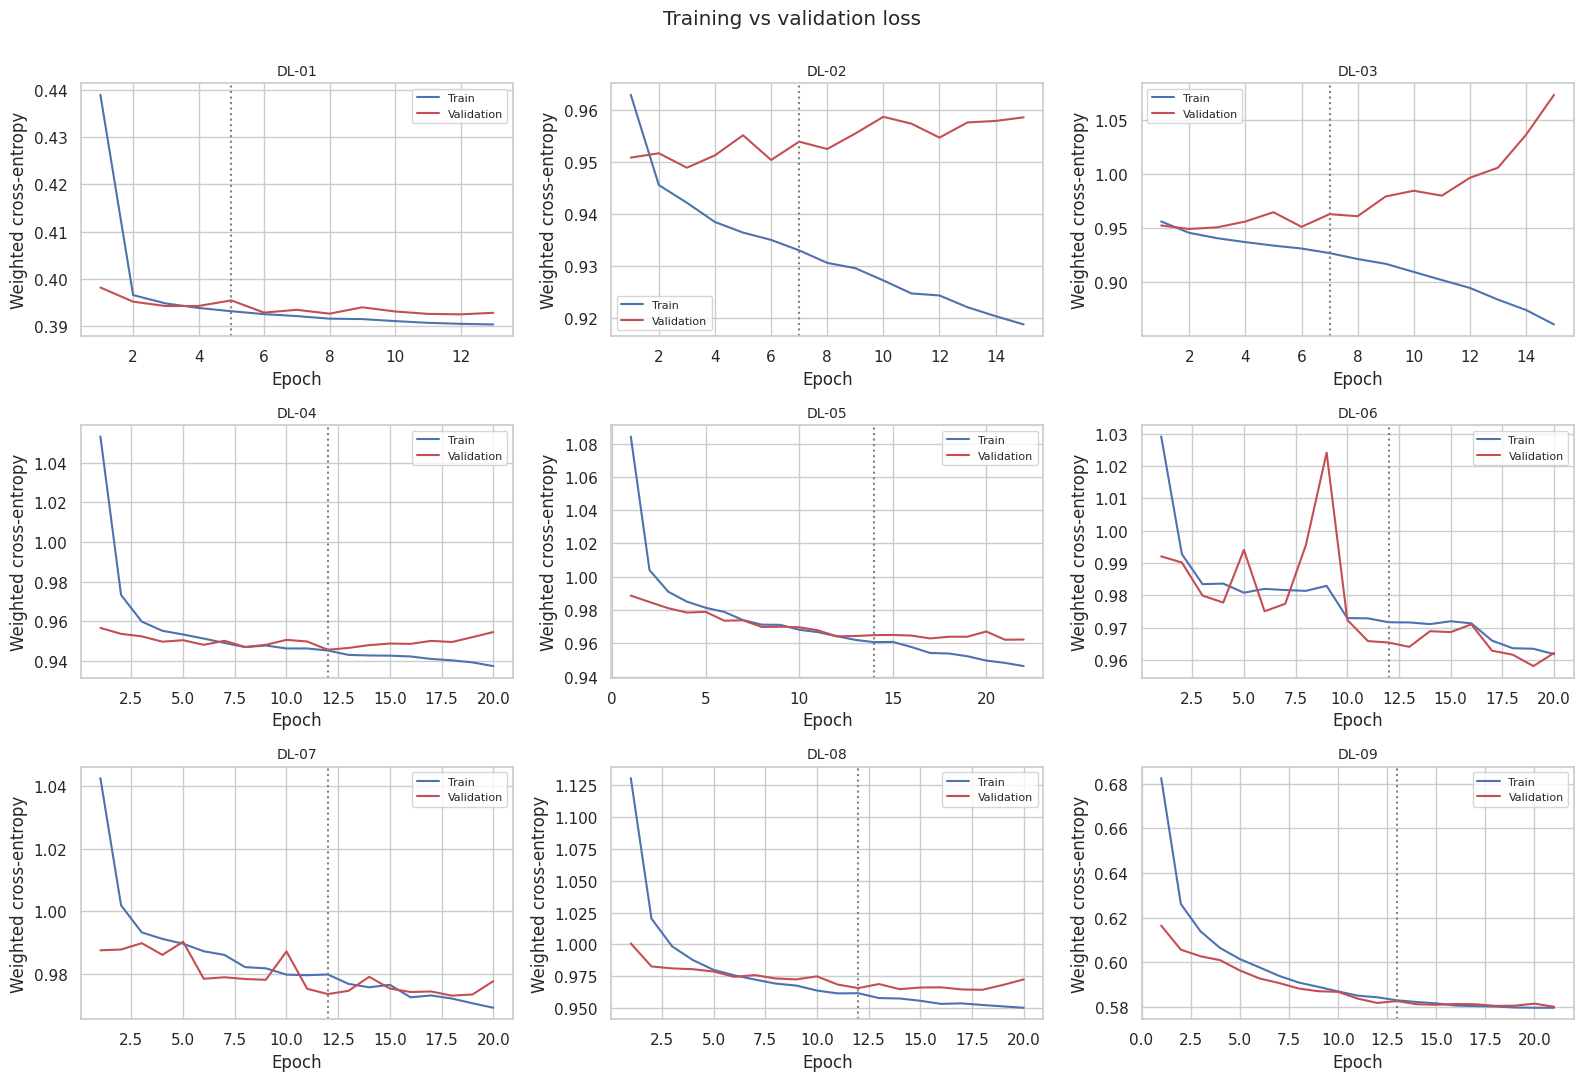

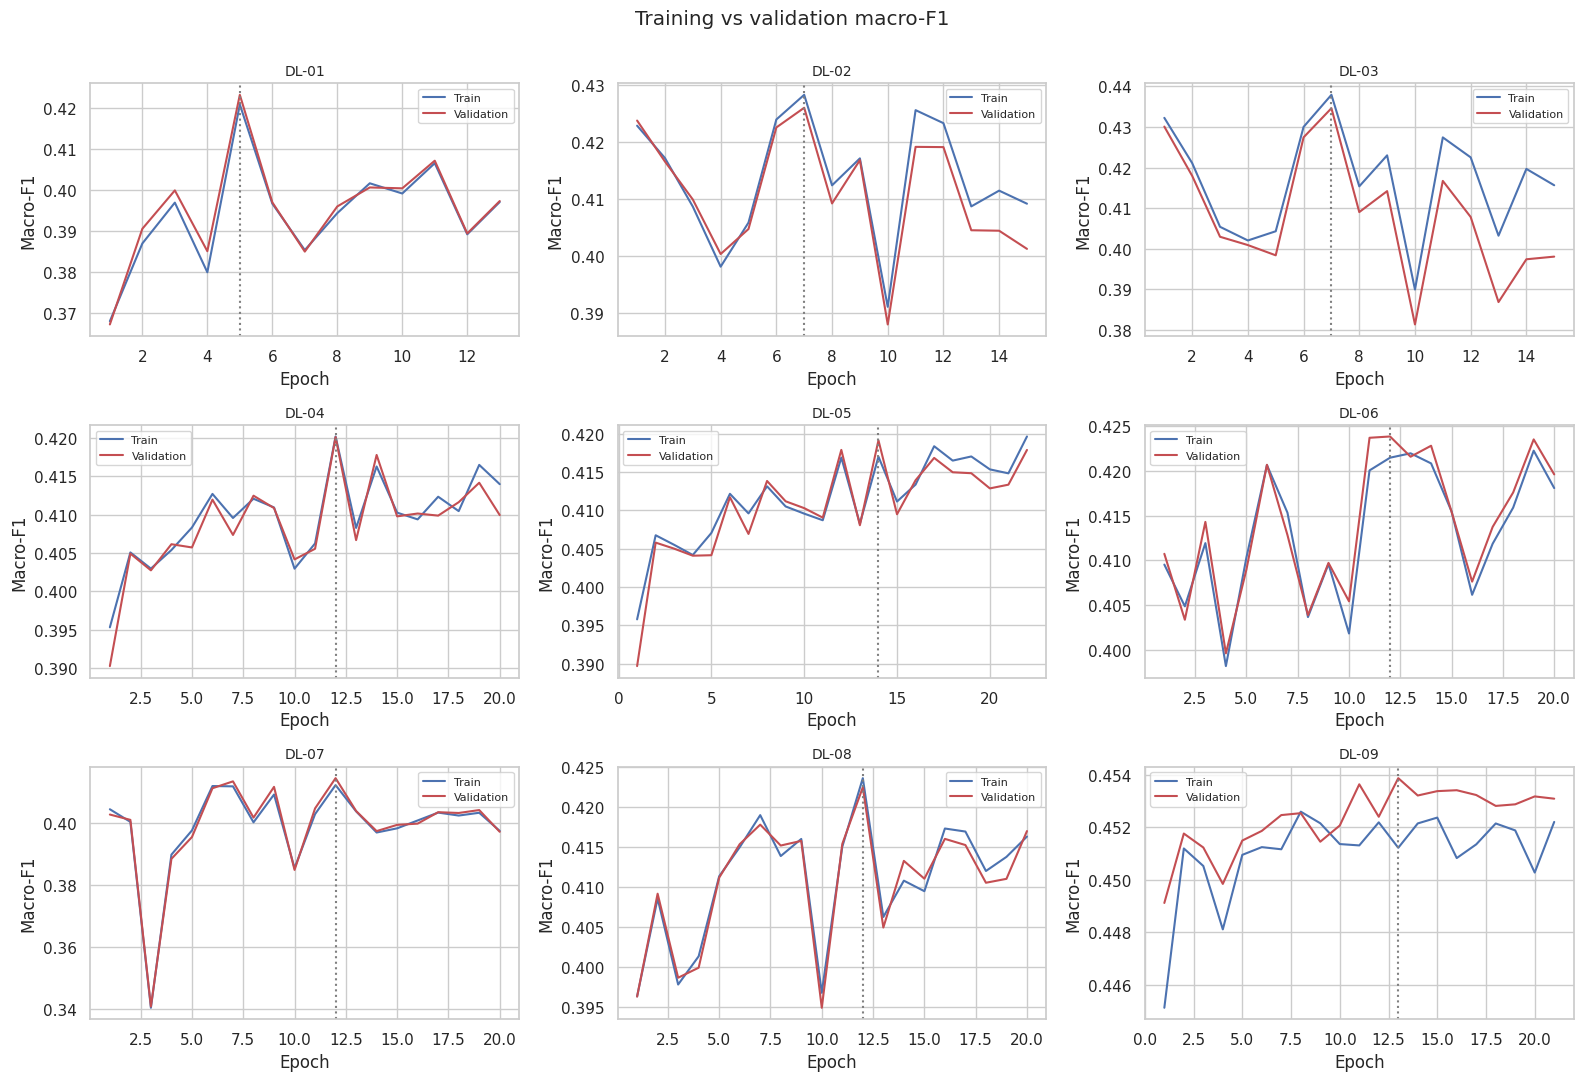

In [43]:
def plot_dl_curves(metric_pair, ylabel, fname, title):
    ids = list(dl_runs.keys())
    ncols = 3
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.6 * nrows), sharey=False)
    for ax, exp_id in zip(axes.flat, ids):
        hist = dl_runs[exp_id][1]
        tr, va = hist[metric_pair[0]], hist[metric_pair[1]]
        epochs = np.arange(1, len(tr) + 1)
        ax.plot(epochs, tr, label="Train", color="#4C72B0")
        ax.plot(epochs, va, label="Validation", color="#C44E52")
        ax.axvline(int(np.argmax(hist["val_macro_f1"])) + 1, ls=":", color="grey")
        ax.set_title(exp_id, fontsize=10)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.legend(fontsize=8)
    for ax in list(axes.flat)[len(ids):]:
        ax.axis("off")
    fig.suptitle(title, y=1.0)
    save_fig(fname)

plot_dl_curves(("loss", "val_loss"), "Weighted cross-entropy", "15_dl_loss_curves",
               "Training vs validation loss")
plot_dl_curves(("train_macro_f1", "val_macro_f1"), "Macro-F1", "16_dl_f1_curves",
               "Training vs validation macro-F1")

_Interpretation of the learning curves (write after running): DL-01 has no class weights, so its loss is on a different scale from the others and should not be compared directly. Focus on the gap between the lines in DL-03 vs DL-04/05, and on how jumpy DL-06 is._

In [44]:
dl_cols = ["exp_id", "model", "imbalance", "train_macro_f1", "macro_f1", "balanced_accuracy", "roc_auc_macro",
           "pr_auc_macro", "recall_no_diab", "recall_prediab", "recall_diab", "precision_diab",
           "accuracy", "best_epoch", "epochs_run", "train_time_s"]
dl_results = tracker.table(dl_cols)
dl_results = dl_results[dl_results["exp_id"].str.startswith("DL")]
dl_results.round(4)

,exp_id,model,imbalance,train_macro_f1,macro_f1,balanced_accuracy,roc_auc_macro,pr_auc_macro,recall_no_diab,recall_prediab,recall_diab,precision_diab,accuracy,best_epoch,epochs_run,train_time_s
12,DL-01,MLP (64-32),none,0.4209,0.4233,0.4101,0.7856,0.4755,0.9632,0.0000,0.2673,0.5221,0.8486,5.0,13.0,30.8
13,DL-02,MLP (64-32),class weights,0.4283,0.4260,0.5218,0.7676,0.4677,0.6478,0.3055,0.6120,0.3596,0.6366,7.0,15.0,39.4
14,DL-03,MLP (256-128-64),class weights,0.4379,0.4346,0.5255,0.7700,0.4695,0.6749,0.2968,0.6049,0.3681,0.6582,7.0,15.0,59.6
15,DL-04,MLP (256-128-64) + dropout/BN,class weights,0.4202,0.4201,0.5255,0.7758,0.4703,0.6245,0.2752,0.6767,0.3385,0.6254,12.0,20.0,130.6
16,DL-05,MLP (256-128-64) + dropout/BN/L2,class weights,0.4170,0.4191,0.5310,0.7721,0.4702,0.6057,0.3516,0.6358,0.3626,0.6053,14.0,22.0,148.8
17,DL-06,"MLP (DL-05 setup), lr 0.01",class weights,0.4215,0.4239,0.5269,0.7767,0.4661,0.6501,0.2536,0.6771,0.3229,0.6467,12.0,20.0,131.5
18,DL-07,"MLP (DL-05 setup), SGD",class weights,0.4122,0.4145,0.5283,0.7733,0.4709,0.6007,0.2752,0.7090,0.3322,0.6098,12.0,20.0,133.4
19,DL-08,Wide & Deep,class weights,0.4236,0.4225,0.5279,0.7739,0.4685,0.6364,0.3242,0.6232,0.3478,0.6288,12.0,20.0,130.0
20,DL-09,"Wide & Deep, sqrt weights",class weights (sqrt-balanced),0.4512,0.4539,0.4730,0.7841,0.4753,0.8820,0.0000,0.5372,0.4132,0.8179,13.0,21.0,137.7


## 20. Closer look at the best network

As in Part 2, I pick the run with the highest validation macro-F1 and inspect it before touching the test set. I save it in the native `.keras` format and also as `.h5` for compatibility. Both files go in the Google Drive folder, together with `artifacts/preprocessor.joblib`, which the network needs to turn raw survey answers into its inputs.

Best deep learning model: DL-09


Model: "wide_and_deep"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ survey_features     │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_29 (Dense)    │ (None, 256)       │      7,680 │ survey_features[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_29[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_22       │ (None, 256)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 256)       │          0 │ activation_22[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_30 (Dense)    │ (None, 128)       │     32,768 │ dropout_15[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_30[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_23       │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 128)       │          0 │ activation_23[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_31 (Dense)    │ (None, 64)        │      8,192 │ dropout_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_31[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_24       │ (None, 64)        │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_17          │ (None, 64)        │          0 │ activation_24[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ wide_logits (Dense) │ (None, 3)         │         93 │ survey_features[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_logits (Dense) │ (None, 3)         │        195 │ dropout_17[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_logits     │ (None, 3)         │          0 │ wide_logits[0][0… │
│ (Add)               │                   │            │ deep_logits[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ probabilities       │ (None, 3)         │          0 │ combined_logits[… │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 150,370 (587.39 KB)

 Trainable params: 49,824 (194.62 KB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 99,650 (389.26 KB)

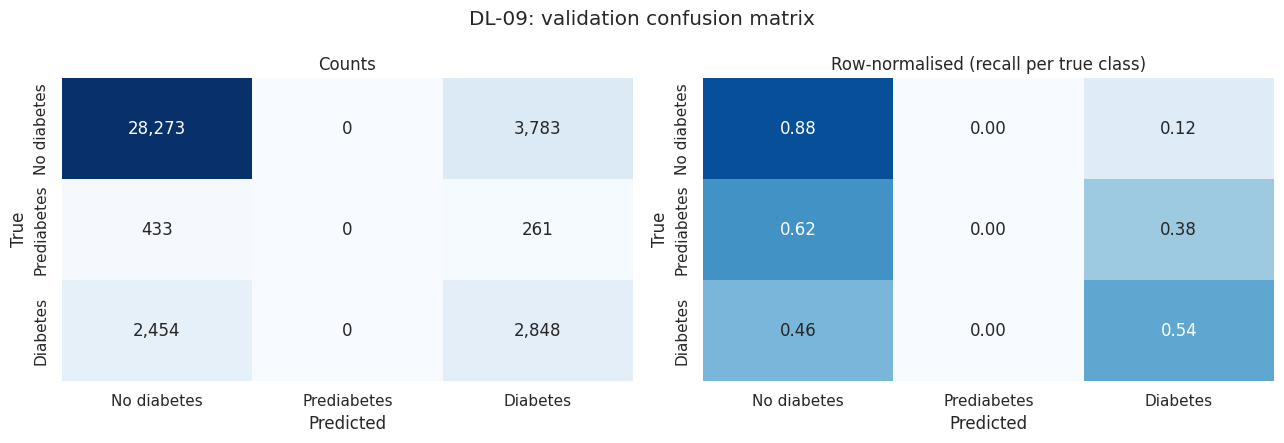

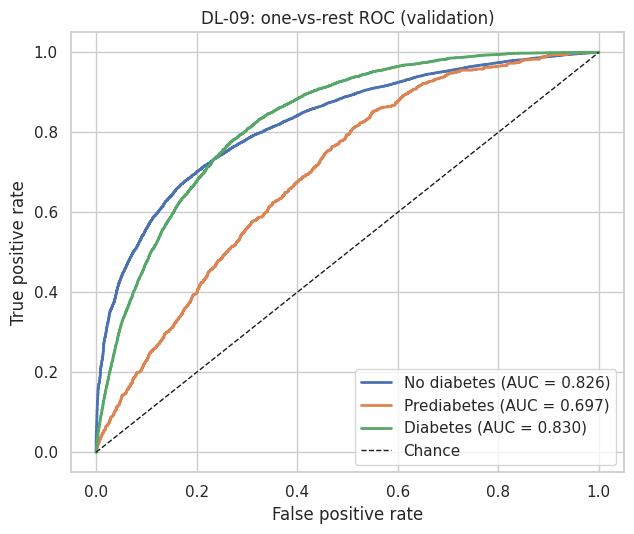

Saved and verified: artifacts/best_deep_learning_model_DL-09.keras


In [45]:
best_dl_id = dl_results.sort_values("macro_f1", ascending=False).iloc[0]["exp_id"]
best_dl_model = dl_runs[best_dl_id][0]
print(f"Best deep learning model: {best_dl_id}")
best_dl_model.summary()

val_proba_dl = best_dl_model.predict(X_val, batch_size=4096, verbose=0)
cm_dl = plot_confusion_matrices(y_val, val_proba_dl.argmax(axis=1), CLASS_NAMES,
                                f"{best_dl_id}: validation confusion matrix",
                                os.path.join(FIG_DIR, "17_dl_best_confusion_matrix.png"))
plot_roc_curves(y_val, val_proba_dl, CLASS_NAMES, f"{best_dl_id}: one-vs-rest ROC (validation)",
                os.path.join(FIG_DIR, "18_dl_best_roc.png"))

dl_model_path = os.path.join(ART_DIR, f"best_deep_learning_model_{best_dl_id}.keras")
best_dl_model.save(dl_model_path)
best_dl_model.save(dl_model_path.replace(".keras", ".h5"))
reloaded_dl = keras.models.load_model(dl_model_path)
assert np.allclose(reloaded_dl.predict(X_val[:100], verbose=0), val_proba_dl[:100], atol=1e-5)
print(f"Saved and verified: {dl_model_path}")

_Interpretation of the best network's confusion matrix and ROC curves (write after running)._

To explore the training runs interactively, run `%load_ext tensorboard` and then `%tensorboard --logdir logs/tensorboard` in a new cell.

---
# Part 4: Final comparison on the test set and error analysis

Up to this point every decision (hyperparameters, feature sets, imbalance strategy, which model is "best") was made on the validation set. The test set has not been used at all, so it gives an honest estimate of how each approach would do on new respondents. I evaluate the best traditional model and the best network on it exactly once.

To show how much the test scores could move by chance, I add 95% bootstrap confidence intervals: I resample the test set with replacement 300 times and recompute the metric each time.

In [46]:
from src.experiments import compute_metrics
from sklearn.metrics import precision_recall_curve, f1_score, roc_auc_score

X_test_ml = select(best_ml_prep.transform(X_test_raw), best_ml_cols)

start = time.time(); test_proba_ml = best_ml_model.predict_proba(X_test_ml); ml_infer = time.time() - start
start = time.time(); test_proba_dl = best_dl_model.predict(X_test, batch_size=4096, verbose=0); dl_infer = time.time() - start

def bootstrap_ci(y_true, y_proba, n_boot=300, seed=SEED):
    rng = np.random.RandomState(seed)
    y_true = np.asarray(y_true)
    f1s, aucs = [], []
    for _ in range(n_boot):
        idx = rng.randint(0, len(y_true), len(y_true))
        f1s.append(f1_score(y_true[idx], y_proba[idx].argmax(1), average="macro"))
        aucs.append(roc_auc_score(y_true[idx], y_proba[idx], multi_class="ovr", average="macro"))
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(aucs, [2.5, 97.5])

rows = []
for label, exp_id, proba, infer, path in [
    ("Traditional ML", best_ml_id, test_proba_ml, ml_infer, ml_model_path),
    ("Deep Learning", best_dl_id, test_proba_dl, dl_infer, dl_model_path),
]:
    m = compute_metrics(y_test, proba)
    f1_ci, auc_ci = bootstrap_ci(y_test, proba)
    train_time = tracker.table().set_index("exp_id").loc[exp_id, "train_time_s"]
    rows.append({"approach": label, "exp_id": exp_id, **m,
                 "macro_f1_95ci": f"[{f1_ci[0]:.3f}, {f1_ci[1]:.3f}]",
                 "roc_auc_95ci": f"[{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]",
                 "train_time_s": train_time,
                 "inference_ms_per_1k": round(infer / len(y_test) * 1000 * 1000, 2),
                 "model_file_mb": round(os.path.getsize(path) / 1e6, 2)})

test_results = pd.DataFrame(rows).set_index("approach")
test_results.to_csv(os.path.join(ART_DIR, "test_results.csv"))
test_results[["exp_id", "macro_f1", "macro_f1_95ci", "roc_auc_macro", "roc_auc_95ci", "pr_auc_macro",
              "balanced_accuracy", "accuracy", "recall_no_diab", "recall_prediab", "recall_diab",
              "precision_prediab", "precision_diab", "train_time_s", "inference_ms_per_1k",
              "model_file_mb"]].T

approach,Traditional ML,Deep Learning
exp_id,ML-04,DL-09
macro_f1,0.448355,0.453884
macro_f1_95ci,"[0.444, 0.453]","[0.450, 0.458]"
roc_auc_macro,0.780888,0.782993
roc_auc_95ci,"[0.773, 0.788]","[0.775, 0.790]"
pr_auc_macro,0.470709,0.475017
balanced_accuracy,0.460749,0.473615
accuracy,0.82043,0.817408
recall_no_diab,0.892996,0.881048
recall_prediab,0.0,0.0


_Interpretation of the test results (write after running): do the confidence intervals overlap? If they do, the two approaches are not meaningfully different in performance, and the choice comes down to cost and interpretability._

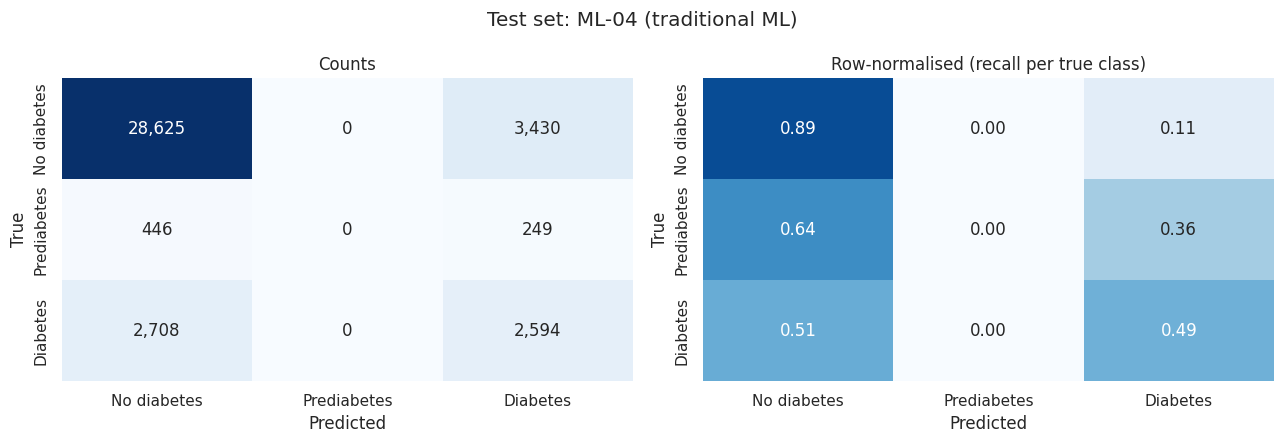

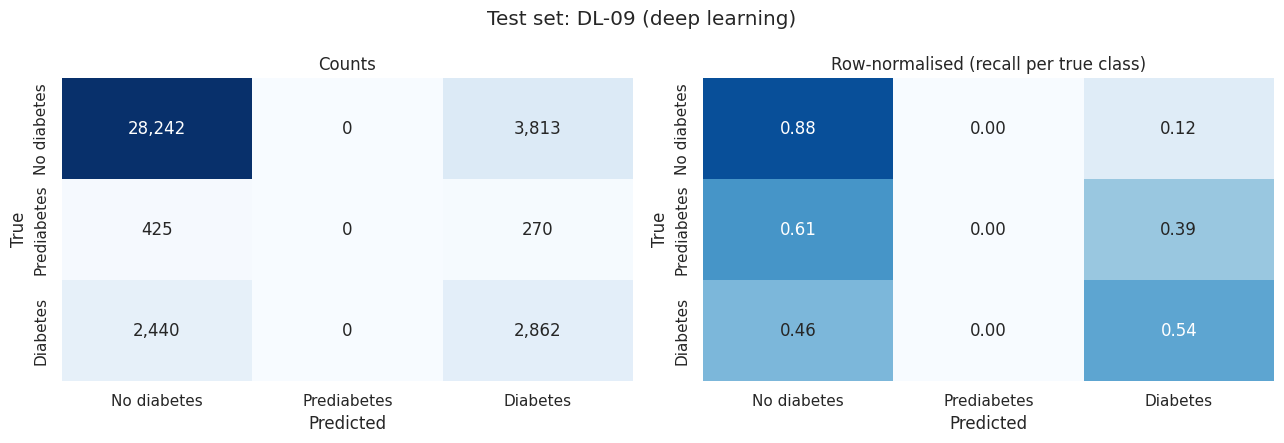

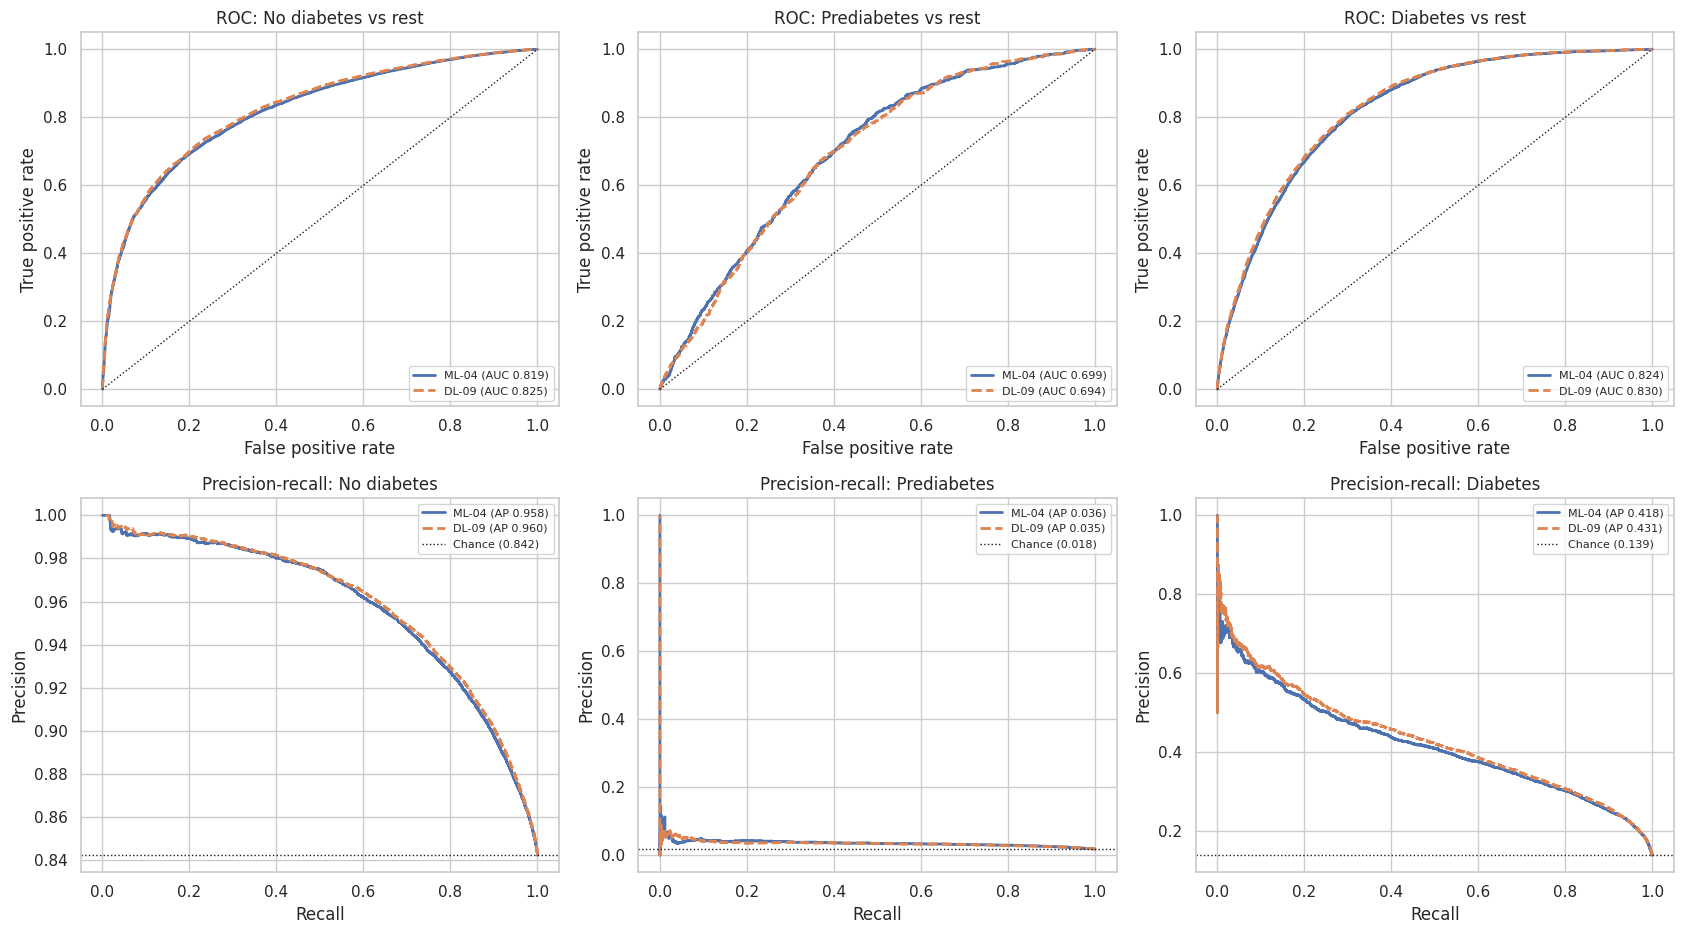

In [47]:
plot_confusion_matrices(y_test, test_proba_ml.argmax(1), CLASS_NAMES, f"Test set: {best_ml_id} (traditional ML)",
                        os.path.join(FIG_DIR, "19_test_confusion_ml.png"))
plot_confusion_matrices(y_test, test_proba_dl.argmax(1), CLASS_NAMES, f"Test set: {best_dl_id} (deep learning)",
                        os.path.join(FIG_DIR, "20_test_confusion_dl.png"))

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, average_precision_score
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
for i, name in enumerate(CLASS_NAMES):
    for proba, label, ls in [(test_proba_ml, best_ml_id, "-"), (test_proba_dl, best_dl_id, "--")]:
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
        axes[0, i].plot(fpr, tpr, ls=ls, lw=2,
                        label=f"{label} (AUC {roc_auc_score(y_test_bin[:, i], proba[:, i]):.3f})")
        prec, rec, _ = precision_recall_curve(y_test_bin[:, i], proba[:, i])
        axes[1, i].plot(rec, prec, ls=ls, lw=2,
                        label=f"{label} (AP {average_precision_score(y_test_bin[:, i], proba[:, i]):.3f})")
    axes[0, i].plot([0, 1], [0, 1], "k:", lw=1)
    axes[0, i].set(title=f"ROC: {name} vs rest", xlabel="False positive rate", ylabel="True positive rate")
    prevalence = y_test_bin[:, i].mean()
    axes[1, i].axhline(prevalence, color="k", ls=":", lw=1, label=f"Chance ({prevalence:.3f})")
    axes[1, i].set(title=f"Precision-recall: {name}", xlabel="Recall", ylabel="Precision")
    axes[0, i].legend(loc="lower right", fontsize=8)
    axes[1, i].legend(loc="upper right", fontsize=8)
save_fig("21_test_roc_and_pr_curves")

_Interpretation of ROC vs precision–recall (write after running). The key point: ROC-AUC can look decent for prediabetes because the "no diabetes" class is so large that even many false positives make only a small false-positive rate. The precision–recall curve, whose chance line is the class prevalence (under 2% for prediabetes), shows how hard that class really is._

## 21. Error analysis

### 21.1 Do the two models make the same mistakes?

If both models fail on the same respondents, the problem is more likely in the data (those people look healthy on paper) than in either model.

In [48]:
ml_correct = test_proba_ml.argmax(1) == y_test.values
dl_correct = test_proba_dl.argmax(1) == y_test.values
agreement = pd.crosstab(pd.Series(ml_correct, name=f"{best_ml_id} correct"),
                        pd.Series(dl_correct, name=f"{best_dl_id} correct"), normalize="all") * 100
print(f"Both wrong on {(~ml_correct & ~dl_correct).mean():.1%} of test respondents")
agreement.round(1)

Both wrong on 16.2% of test respondents


DL-09 correct,False,True
ML-04 correct,,
False,16.2,1.7
True,2.0,80.0


### 21.2 What do the missed diabetes cases look like?

The most costly error in screening is telling someone with diabetes that they are fine. I compare respondents with diabetes that the final model caught with those it labelled "no diabetes", using their original (unscaled) answers.

The final model is the one with the higher **validation** macro-F1. I choose it this way, and not by test score, so the test set stays a fair, untouched estimate.

In [49]:
val_scores = {best_ml_id: tracker.table().set_index("exp_id").loc[best_ml_id, "macro_f1"],
              best_dl_id: tracker.table().set_index("exp_id").loc[best_dl_id, "macro_f1"]}
final_id = max(val_scores, key=val_scores.get)
final_test_proba = test_proba_ml if final_id == best_ml_id else test_proba_dl
final_val_proba = val_proba_ml if final_id == best_ml_id else val_proba_dl
final_pred = final_test_proba.argmax(1)
print(f"Final model (chosen on validation macro-F1): {final_id}")

test_view = X_test_raw.copy()
test_view["true"], test_view["pred"] = y_test.values, final_pred
diab = test_view[test_view["true"] == 2]
compare_cols = ["BMI", "HighBP", "HighChol", "GenHlth", "Age", "DiffWalk", "HeartDiseaseorAttack",
                "PhysActivity", "Income", "PhysHlth"]
error_profile = pd.DataFrame({
    "caught (pred diabetes)": diab[diab["pred"] == 2][compare_cols].mean(),
    "missed (pred no diabetes)": diab[diab["pred"] == 0][compare_cols].mean(),
    "all no-diabetes respondents": test_view[test_view["true"] == 0][compare_cols].mean(),
}).round(2)
print(f"Respondents with diabetes in test set: {len(diab):,} | caught {np.mean(diab['pred'] == 2):.1%} | "
      f"missed as no diabetes {np.mean(diab['pred'] == 0):.1%} | labelled prediabetes {np.mean(diab['pred'] == 1):.1%}")
error_profile

Final model (chosen on validation macro-F1): DL-09
Respondents with diabetes in test set: 5,302 | caught 54.0% | missed as no diabetes 46.0% | labelled prediabetes 0.0%


,caught (pred diabetes),missed (pred no diabetes),all no-diabetes respondents
BMI,34.89,28.58,27.73
HighBP,0.91,0.57,0.37
HighChol,0.80,0.53,0.38
GenHlth,3.78,2.72,2.38
Age,9.62,9.09,7.76
DiffWalk,0.53,0.17,0.13
HeartDiseaseorAttack,0.32,0.10,0.07
PhysActivity,0.54,0.75,0.78
Income,4.61,5.91,6.22
PhysHlth,10.98,4.25,3.58


_Interpretation of the error profile (write after running): if the missed cases look much closer to the no-diabetes group than to the caught cases (lower BMI, less high blood pressure, better self-rated health), then the survey answers simply do not contain enough signal for these people. That is a data limitation, not something more tuning can fix._

### 21.3 Does performance differ across groups?

A screening tool that works well for one group and poorly for another could widen existing health gaps. I check diabetes recall and macro-F1 across sex, age group and income group.

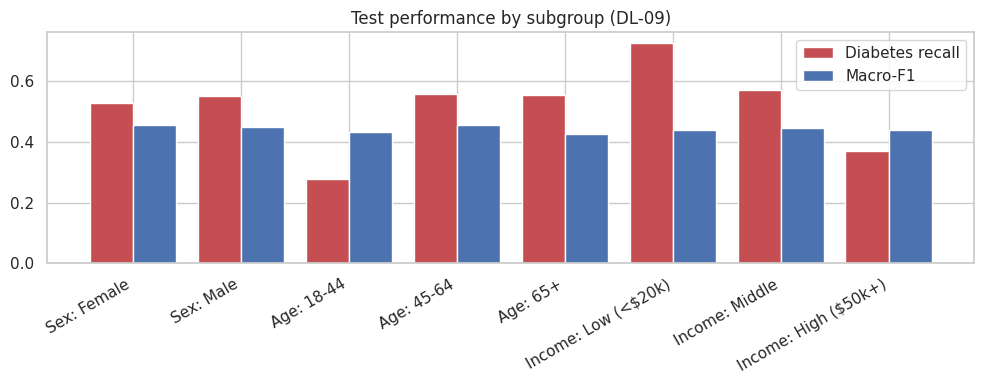

,group,level,n,diabetes_prevalence,recall_diab,macro_f1
0,Sex,Female,21289,0.130,0.528,0.456
1,Sex,Male,16763,0.151,0.553,0.450
2,Age,18-44,8235,0.042,0.278,0.432
3,Age,45-64,21464,0.149,0.560,0.456
4,Age,65+,8353,0.212,0.555,0.426
5,Income,Low (<$20k),5539,0.246,0.725,0.439
6,Income,Middle,12408,0.166,0.572,0.447
7,Income,High ($50k+),20105,0.094,0.370,0.438


In [50]:
age_group = pd.cut(X_test_raw["Age"], [0, 5, 10, 13], labels=["18-44", "45-64", "65+"])
income_group = pd.cut(X_test_raw["Income"], [0, 3, 6, 8], labels=["Low (<$20k)", "Middle", "High ($50k+)"])
sex_group = X_test_raw["Sex"].map({0: "Female", 1: "Male"})

sub_rows = []
for gname, groups in [("Sex", sex_group), ("Age", age_group), ("Income", income_group)]:
    for level in groups.cat.categories if hasattr(groups, "cat") else sorted(groups.unique()):
        mask = (groups == level).values
        yt, yp = y_test.values[mask], final_pred[mask]
        sub_rows.append({"group": gname, "level": level, "n": int(mask.sum()),
                         "diabetes_prevalence": (yt == 2).mean(),
                         "recall_diab": (yp[yt == 2] == 2).mean() if (yt == 2).any() else np.nan,
                         "macro_f1": f1_score(yt, yp, average="macro", zero_division=0)})
subgroups = pd.DataFrame(sub_rows)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(subgroups))
ax.bar(x - 0.2, subgroups["recall_diab"], 0.4, label="Diabetes recall", color=CLASS_COLORS[2])
ax.bar(x + 0.2, subgroups["macro_f1"], 0.4, label="Macro-F1", color="#4C72B0")
ax.set_xticks(x, subgroups["group"] + ": " + subgroups["level"].astype(str), rotation=30, ha="right")
ax.set_title(f"Test performance by subgroup ({final_id})")
ax.legend()
save_fig("22_subgroup_performance")
subgroups.round(3)

_Interpretation of subgroup performance (write after running)._

## 22. From probabilities to a screening decision

In a real screening setting, the goal would be to flag anyone who might have diabetes **or** prediabetes and send them for a blood test. So instead of taking the most likely class, I add up the predicted probabilities for prediabetes and diabetes to get a single "at-risk" score, and choose a cut-off for it.

I set the cut-off on the **validation** set so that 80% of at-risk people are caught, then check what that cut-off does on the test set. The trade-off is direct: catching more people means referring more healthy people for tests they did not need.

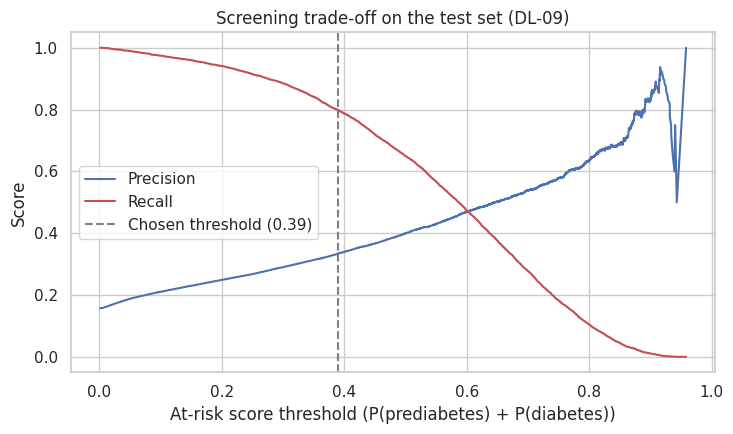

,threshold,recall (at-risk caught),precision (flagged who are at risk),share of people referred
argmax (default),0.50,0.522,0.451,0.183
threshold for 80% recall (set on validation),0.39,0.799,0.334,0.377


In [51]:
y_val_risk = (y_val.values > 0).astype(int)
y_test_risk = (y_test.values > 0).astype(int)
val_risk_score = final_val_proba[:, 1] + final_val_proba[:, 2]
test_risk_score = final_test_proba[:, 1] + final_test_proba[:, 2]

prec_v, rec_v, thr_v = precision_recall_curve(y_val_risk, val_risk_score)
TARGET_RECALL = 0.80
threshold = thr_v[np.where(rec_v[:-1] >= TARGET_RECALL)[0][-1]]

def screening_summary(y_true, score, thr):
    flagged = score >= thr
    tp = (flagged & (y_true == 1)).sum()
    return {"threshold": round(float(thr), 3), "recall (at-risk caught)": tp / (y_true == 1).sum(),
            "precision (flagged who are at risk)": tp / max(flagged.sum(), 1),
            "share of people referred": flagged.mean()}

screening = pd.DataFrame({
    "argmax (default)": screening_summary(y_test_risk, (final_test_proba.argmax(1) > 0).astype(float), 0.5),
    f"threshold for {TARGET_RECALL:.0%} recall (set on validation)": screening_summary(y_test_risk, test_risk_score, threshold),
}).T.round(3)

prec_t, rec_t, thr_t = precision_recall_curve(y_test_risk, test_risk_score)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(thr_t, prec_t[:-1], label="Precision", color="#4C72B0")
ax.plot(thr_t, rec_t[:-1], label="Recall", color="#C44E52")
ax.axvline(threshold, ls="--", color="grey", label=f"Chosen threshold ({threshold:.2f})")
ax.set_xlabel("At-risk score threshold (P(prediabetes) + P(diabetes))")
ax.set_ylabel("Score")
ax.set_title(f"Screening trade-off on the test set ({final_id})")
ax.legend()
save_fig("23_screening_threshold")
screening

_Interpretation of the screening trade-off (write after running)._

## 23. Conclusions

_Write after running. This section should cover: which approach won and by how much (using the confidence intervals); the accuracy–interpretability–cost trade-off between logistic regression, boosting and the neural network; the bias–variance picture from the learning curves; the main error patterns (prediabetes confused with both neighbours, missed diabetes cases that look healthy on paper); the dataset limitations (self-reported data, noisy prediabetes labels, US-only survey from 2015, kept duplicates); and future work._

In [52]:
print("Files to upload to the Google Drive folder:")
for f in sorted(os.listdir(ART_DIR)):
    print(f"  artifacts/{f}  ({os.path.getsize(os.path.join(ART_DIR, f)) / 1e6:.2f} MB)")
print(f"\nFigures for the report are in {FIG_DIR}/ ({len(os.listdir(FIG_DIR))} files)")
print("Experiment logs: logs/wandb (W&B offline runs) and logs/tensorboard")

Files to upload to the Google Drive folder:
  artifacts/best_deep_learning_model_DL-09.h5  (0.68 MB)
  artifacts/best_deep_learning_model_DL-09.keras  (0.68 MB)
  artifacts/best_traditional_model_ML-04.joblib  (0.01 MB)
  artifacts/experiment_log.csv  (0.01 MB)
  artifacts/metadata.json  (0.00 MB)
  artifacts/preprocessor.joblib  (0.00 MB)
  artifacts/processed_splits.npz  (3.14 MB)
  artifacts/test_results.csv  (0.00 MB)

Figures for the report are in figures/ (23 files)
Experiment logs: logs/wandb (W&B offline runs) and logs/tensorboard
